# Macao daily arrivals: recovery, composition and calendar models

## Research overview and reading guide

This notebook uses historical daily visitor statistics from the Statistics and Census Service of Macao (DSEC). It examines recovery through total arrivals, daily distributions, source composition, overnight composition and calendar-model performance. The unit is **visitor arrivals on a date**, not an individual traveller. One person can contribute several arrivals. The source table contains 17 groups, including countries, territories and continental aggregates. Source means the place of issue of the travel document, not nationality or residence. Overnight arrivals are not hotel guests or room nights. See the [data definitions](data/README.txt).

| Research question | Exact question | Role of this notebook |
|---|---|---|
| RQ1 | How did total arrivals, overnight/same-day composition and source composition change between 2019 and 2025? | Annual totals, source shares and changes, and overnight/same-day composition |
| RQ2 | How did the typical level, spread and upper quantiles of daily arrivals change, and did changes vary by month and weekday? | Distributions, quantiles and calendar strata; a fixed historical threshold for high-arrival dates |
| RQ3 | How did calendar models selected using 2024 validation perform in 2025, and how did trend and Ridge affect errors? | A weekday baseline, OLS and Ridge under chronological validation, followed by 2025 error analysis |
| RQ4 | Did arrivals, nominal non-gaming expenditure and official spending per visit recover together under same-quarter and annual comparisons? | Arrival counts and type composition for the [spending notebook](spending_analysis.ipynb) |

For each of the seven code cells, read the purpose and course links, then the code and output, and finally the interpretation. Numerical explanations must be checked again if inputs or models change; prose does not update automatically.

Read the [fixed analysis protocol](protocol.txt) first. Descriptions cover 2017–2025. Models use 2023 as the initial training year, the four quarters of 2024 for expanding-window validation, and 2025 as the historical holdout. Real high and low observations are retained. Missing values are not silently replaced with zero. We do not make causal claims or treat daily records as independent random draws for significance testing. **2025 is excluded from fitting and model/alpha selection, but was already examined in the descriptive analysis.** This is not a fully blind study.

Course references below give lecture names, page numbers and available Moodle links. The full directory is on the [course page](https://ummoodle.um.edu.mo/course/view.php?id=46674).

## Code cell 1: environment, paths and consistent summaries

### Purpose and steps

This cell prepares reusable analysis tools; it does not estimate a statistical relationship. pandas handles tables and grouping, NumPy handles numerical arrays, Matplotlib creates static figures, and scikit-learn supplies the later preprocessing, models and metrics.

`ROOT` is the project directory. `DATA`, `RESULTS` and `FIGURES` locate inputs, tables and plots. `save_table()` exports UTF-8 CSV files. `save_figure()` applies a common source note, layout and resolution, saves a PNG and displays that same image in the notebook. Consistent colours identify 2019 and 2025 across figures.

`describe()` defines the number of days, total, mean, median, Q25, Q75, IQR, P90, minimum and maximum. `group_describe()` applies these definitions consistently to every grouping. For example:

$$
\bar{x}=\frac{1}{n}\sum_{d=1}^{n}x_d,\qquad IQR=Q_{0.75}-Q_{0.25}.
$$

The mean spreads total arrivals across days. The median describes the middle-ranked date and is less sensitive to a few very high values. IQR measures the spread of the middle 50% of dates; P90 locates the upper part of the distribution. Interpolated quantiles can have decimals even though arrival counts are integers.

### Course links

- Lecture04, *Introduction to Exploratory Data Analysis*, pp19–45: centre, variation and quantiles. See the [lecture directory](https://ummoodle.um.edu.mo/course/view.php?id=46674).
- Lecture06, *Introduction to Matplotlib*, pp4–7, 8–32, 33–45 and 68–84: Figure/Axes, plots, labels, legends, saving and layouts. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451).
- The [data-wrangling material](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153067) covers data acquisition, DataFrames and categorical encoding. Our helper functions apply these ideas; they are not claimed to be verbatim course examples.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import importlib.metadata
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA, RESULTS, FIGURES = ROOT / "data", ROOT / "results", ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 135, "savefig.dpi": 180,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 12})
COLORS = {2019: "#0072B2", 2025: "#D55E00"}
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def save_table(frame, name):
    frame.to_csv(RESULTS / name, index=False, encoding="utf-8-sig")

def save_figure(name):
    plt.gcf().text(.01, .005, "Source: DSEC daily visitor arrivals; descriptive historical analysis.", fontsize=7, color="#555555")
    plt.tight_layout(rect=(0, .025, 1, 1))
    plt.savefig(FIGURES / name, bbox_inches="tight")
    plt.close()
    # Display the same exported PNG when this script is split into notebook cells.
    if "get_ipython" in globals():
        from IPython.display import Image, display
        display(Image(filename=str(FIGURES / name)))

def describe(values):
    return pd.Series({"days": len(values), "total": values.sum(),
                      "mean": values.mean(), "median": values.median(),
                      "q25": values.quantile(.25), "q75": values.quantile(.75),
                      "iqr": values.quantile(.75)-values.quantile(.25),
                      "p90": values.quantile(.9), "min": values.min(), "max": values.max()})

def group_describe(frame, keys, column="visitor_arrivals"):
    return frame.groupby(keys, observed=True)[column].apply(describe).unstack(-1).reset_index()

### Cell 1 interpretation: infrastructure, not a finding

The first execution has no statistical output because it only imports packages and defines paths and functions. Later tables share one set of summary definitions, and plots share one export function. This supports consistency and traceability.

The cell provides the common foundation for RQ1–RQ3 and the arrival summaries used in RQ4. It does not itself answer any research question. Successful imports or image exports are not evidence that a research conclusion is correct.

## Code cell 2: input checks, date alignment and visitor-type flags

### Purpose and steps

Before interpreting recovery, we check completeness, additivity and provenance. The inputs are [daily totals](data/macao_daily_total_2017_2025.csv), [daily source groups](data/macao_daily_source_2017_2025.csv), and [daily visitor types](data/macao_daily_total_overnight_sameday_2017_2025.csv). Dates are parsed as dates; source codes are read as strings because they are categories, not continuous quantities.

Assertions require exactly 3,287 unique dates from 2017-01-01 to 2025-12-31; non-missing, non-negative totals; 17 source groups on each date; unique date/source keys; and non-missing, non-negative source counts. Source dates must match total dates, and the 17 groups must sum exactly to the total each day. The type table must contain the same dates and totals. Failed checks stop execution rather than allowing unexplained discrepancies to pass silently.

Two same-day fields preserve the distinction between observation and derivation: `same_day_raw` holds the published value, while `same_day_analysis` includes one explicitly labelled value previously derived as total minus overnight arrivals. This cell makes no new imputations. It flags raw missingness or non-additivity as `type_anomaly_flag`, records `flag_reason`, and exports both the full table and flagged dates.

Finally, it derives `year`, `month` and `weekday` (Monday = 0, Sunday = 6). `pd.cut` creates the fixed periods 2017–2019, 2020–2022 and 2023–2025. These are descriptive calendar groups, not estimated policy breakpoints.

### Course links

Tutorial04-01, *ThinkStats2 EDA*, pp30–35 covers errors, special values, missing-value codes and derived columns; pp36–42 covers verification. Lecture04 pp29–30 and Tutorial05-01, *Distributions*, pp19–20 explain why an extreme observation may be real and should not be deleted automatically. See the [lecture directory](https://ummoodle.um.edu.mo/course/view.php?id=46674) and the [data-wrangling material](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153067). We use neither multiple imputation nor IQR-based removal of real peaks.

In [2]:
total = pd.read_csv(DATA / "macao_daily_total_2017_2025.csv", parse_dates=["date"]).sort_values("date")
sources = pd.read_csv(DATA / "macao_daily_source_2017_2025.csv", parse_dates=["date"], dtype={"source_code": str})
types = pd.read_csv(DATA / "macao_daily_total_overnight_sameday_2017_2025.csv", parse_dates=["date"])
assert len(total) == 3287 and total.date.is_unique
assert total.date.tolist() == pd.date_range("2017-01-01", "2025-12-31").tolist()
assert total.visitor_arrivals.notna().all() and total.visitor_arrivals.ge(0).all()
assert sources.groupby("date").size().eq(17).all()
assert not sources.duplicated(["date", "source_code"]).any()
assert sources.visitor_arrivals.notna().all() and sources.visitor_arrivals.ge(0).all()
assert set(sources.date) == set(total.date)
source_sums = sources.groupby("date").visitor_arrivals.sum()
assert np.array_equal(source_sums.reindex(total.date).to_numpy(), total.visitor_arrivals.to_numpy())
types = types.sort_values("date")
assert types.date.tolist() == total.date.tolist()
assert np.array_equal(types.total.to_numpy(), total.visitor_arrivals.to_numpy())
types["type_anomaly_flag"] = types.same_day_raw.isna() | types.raw_additivity_residual.fillna(0).ne(0)
types["flag_reason"] = np.select([types.same_day_raw.isna(), types.raw_additivity_residual.fillna(0).ne(0)],
                                 ["missing_same_day_raw_derived_by_difference", "raw_additivity_discrepancy_1_person"], default="none")
assert types.type_anomaly_flag.sum() == 9
save_table(types.loc[types.type_anomaly_flag], "type_anomaly_dates.csv")
save_table(types, "type_data_with_flags.csv")
total["year"], total["month"], total["weekday"] = total.date.dt.year, total.date.dt.month, total.date.dt.dayofweek
total["stage"] = pd.cut(total.year, [2016, 2019, 2022, 2025], labels=["2017-2019", "2020-2022", "2023-2025"])
audit = {"total_days": len(total), "source_rows": len(sources), "source_groups": sources.source_code.nunique(),
         "total_missing": int(total.visitor_arrivals.isna().sum()), "source_additivity_verified": True,
         "type_flagged_dates": int(types.type_anomaly_flag.sum()),
         "type_missing_raw_days": int(types.same_day_raw.isna().sum()),
         "type_nonzero_additivity_days": int(types.raw_additivity_residual.fillna(0).ne(0).sum()),
         "removed_dates": 0, "removed_high_values": 0}
print("Data audit:", audit)

Data audit: {'total_days': 3287, 'source_rows': 55879, 'source_groups': 17, 'total_missing': 0, 'source_additivity_verified': True, 'type_flagged_dates': 9, 'type_missing_raw_days': 1, 'type_nonzero_additivity_days': 8, 'removed_dates': 0, 'removed_high_values': 0}


### Cell 2 interpretation: complete totals and nine transparent type flags

The output confirms **3,287 dates, 55,879 date/source records, 17 source groups, no missing daily totals, and exact daily source additivity**. No dates or high values were removed. These checks establish consistency between the input tables; they do not rule out every possible measurement error in official statistics.

The [flagged-date table](results/type_anomaly_dates.csv) records:

| Issue | Dates | Treatment |
|---|---|---|
| One missing raw same-day value | 2018-09-16 | Total = overnight = 921. Raw same-day remains missing; the analysis value 0 is explicitly derived as 921 − 921. |
| Two type-additivity differences of ±1 arrival | 2019-09-25 and 2019-09-26 | Retain the original values and flag the differences. |
| Four type-additivity differences of ±1 arrival | 2021-01-17, 01-19, 03-12 and 03-13 | Retain and flag. |
| Two type-additivity differences of ±1 arrival | 2022-10-02 and 2022-10-04 | Retain and flag. |

Calling this simply “filling missing data with zero” would be misleading: the zero has an explicit arithmetic basis, but is still not an observed API value. The eight ±1 differences are not adjusted to force equality. A type flag does not imply that the day's total is invalid. All real high and low dates remain in the main analysis. A separate sensitivity branch later excludes flagged dates without changing the main data.

For RQ1, these checks make composition denominators traceable. For RQ2, retaining dates avoids changing the distribution through filtering. For RQ3, totals are complete and type counts are not predictors. For RQ4, type counts can be aggregated by quarter, but do not create daily spending observations. All nine flags predate 2023, so no flagged type values affect the model period.

## Code cell 3: period, annual and conditional distributions

### Purpose and steps

This cell compares total volume, typical dates, upper quantiles and spread rather than answering “recovery” from annual totals alone. It first computes period and annual summaries, then compares 2019 and 2025 by month, weekday, and month × weekday. Because periods contain slightly different numbers of dates, daily means and quantiles are more suitable than totals alone for comparisons of daily intensity.

Four figures show the full daily history; 2019/2025 ECDFs and common-bin density histograms; monthly means and weekday medians; and a year × month heatmap of daily means. The empirical CDF is:

$$
\widehat{F}_n(x)=\frac{1}{n}\sum_{d=1}^{n}\mathbf{1}(x_d\leq x).
$$

The code sorts arrivals and uses `np.arange(1, len(x)+1)/len(x)` for cumulative proportions. At a given arrival count x, the vertical coordinate is the fraction of dates with arrivals no greater than x. Conversely, cumulative levels 0.5 and 0.9 locate the median and P90. The ECDF requires neither normality nor a choice of bins.

Histograms use arrivals in thousands, common bins 10,000 arrivals wide, and `density=True`. **Area**, not bar height alone, represents a proportion. Common bins and scales make the two years comparable. The heatmap uses the **mean per day within each month**, not monthly totals, so differing month lengths do not mechanically drive colour intensity.

### Course links

- Lecture04 pp19–56: means, medians, quantiles, IQR, histograms and distributions; pp85–86: conditioning. Lecture05, *Introduction to Data Visualization Plots*, pp5–9, 37–40 and 61–76: lines, heatmaps and distribution plots. [Directory](https://ummoodle.um.edu.mo/course/view.php?id=46674).
- Tutorial07-01, *CDFs*, pp7–13: percentiles and CDFs; pp14–16: grouped CDFs; pp17–18: medians and IQR. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1241363).
- Lecture06 pp46–67 and 68–84: histograms, scatterplots, subplots and shared axes. `imshow` on p91 and `colorbar` on p95 support the heatmap implementation. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451).
- Tutorial10-01, *Relationships*, pp17–20: groups and conditional quantiles. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266950).

Stage statistics:
     stage   days       total     mean  median     q25      q75     iqr      p90   min      max
2017-2019 1095.0 107820350.0 98466.07 94448.0 83849.0 109509.5 25660.5 127003.2 921.0 226326.0
2020-2022 1096.0  19303130.0 17612.34 17218.0  7920.5  22451.0 14530.5  28366.0 184.0 144805.0
2023-2025 1096.0 103211013.0 94170.63 89783.0 75947.5 109289.0 33341.5 130763.5 711.0 221857.0
Annual statistics:
  year  days      total      mean   median      q25      q75      iqr      p90     min      max
 2017 365.0 32610506.0  89343.85  85848.0 77362.00  98909.0 21547.00 113758.6 20400.0 166048.0
 2018 365.0 35803663.0  98092.23  94391.0 84777.00 108638.0 23861.00 123843.8   921.0 185079.0
 2019 365.0 39406181.0 107962.14 104695.0 90853.00 118016.0 27163.00 138130.0 68310.0 226326.0
 2020 366.0  5896848.0  16111.61   7907.0   905.75  19545.0 18639.25  24959.0   205.0 144805.0
 2021 365.0  7705943.0  21112.17  21576.0 16915.00  27461.0 10546.00  30517.2   350.0  44699.0
 2022 365.0

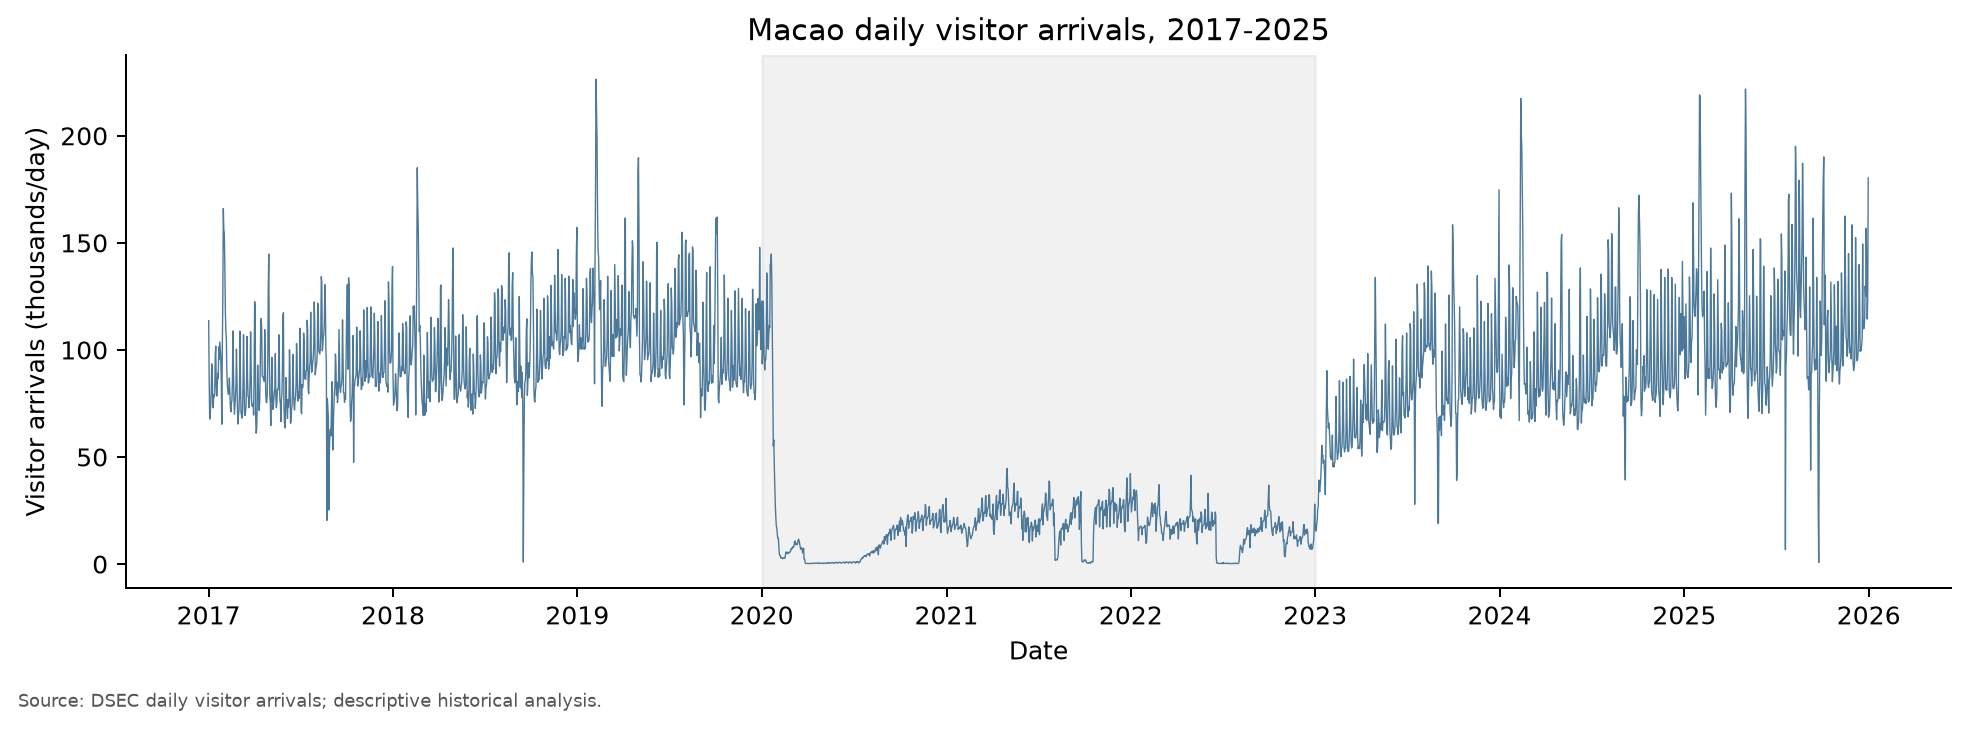

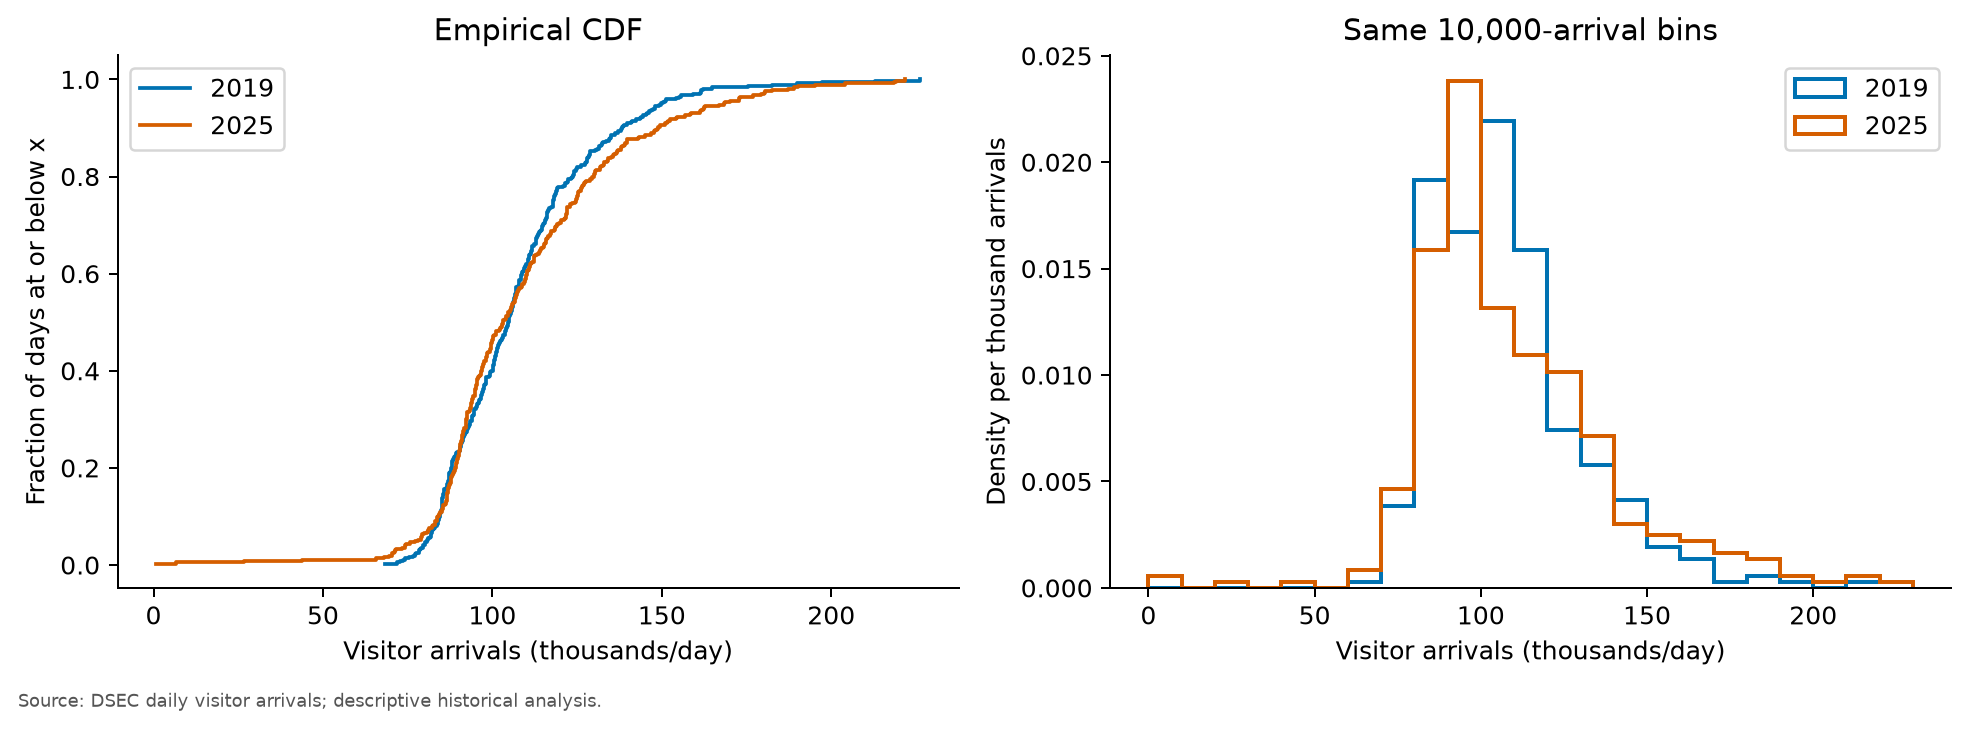

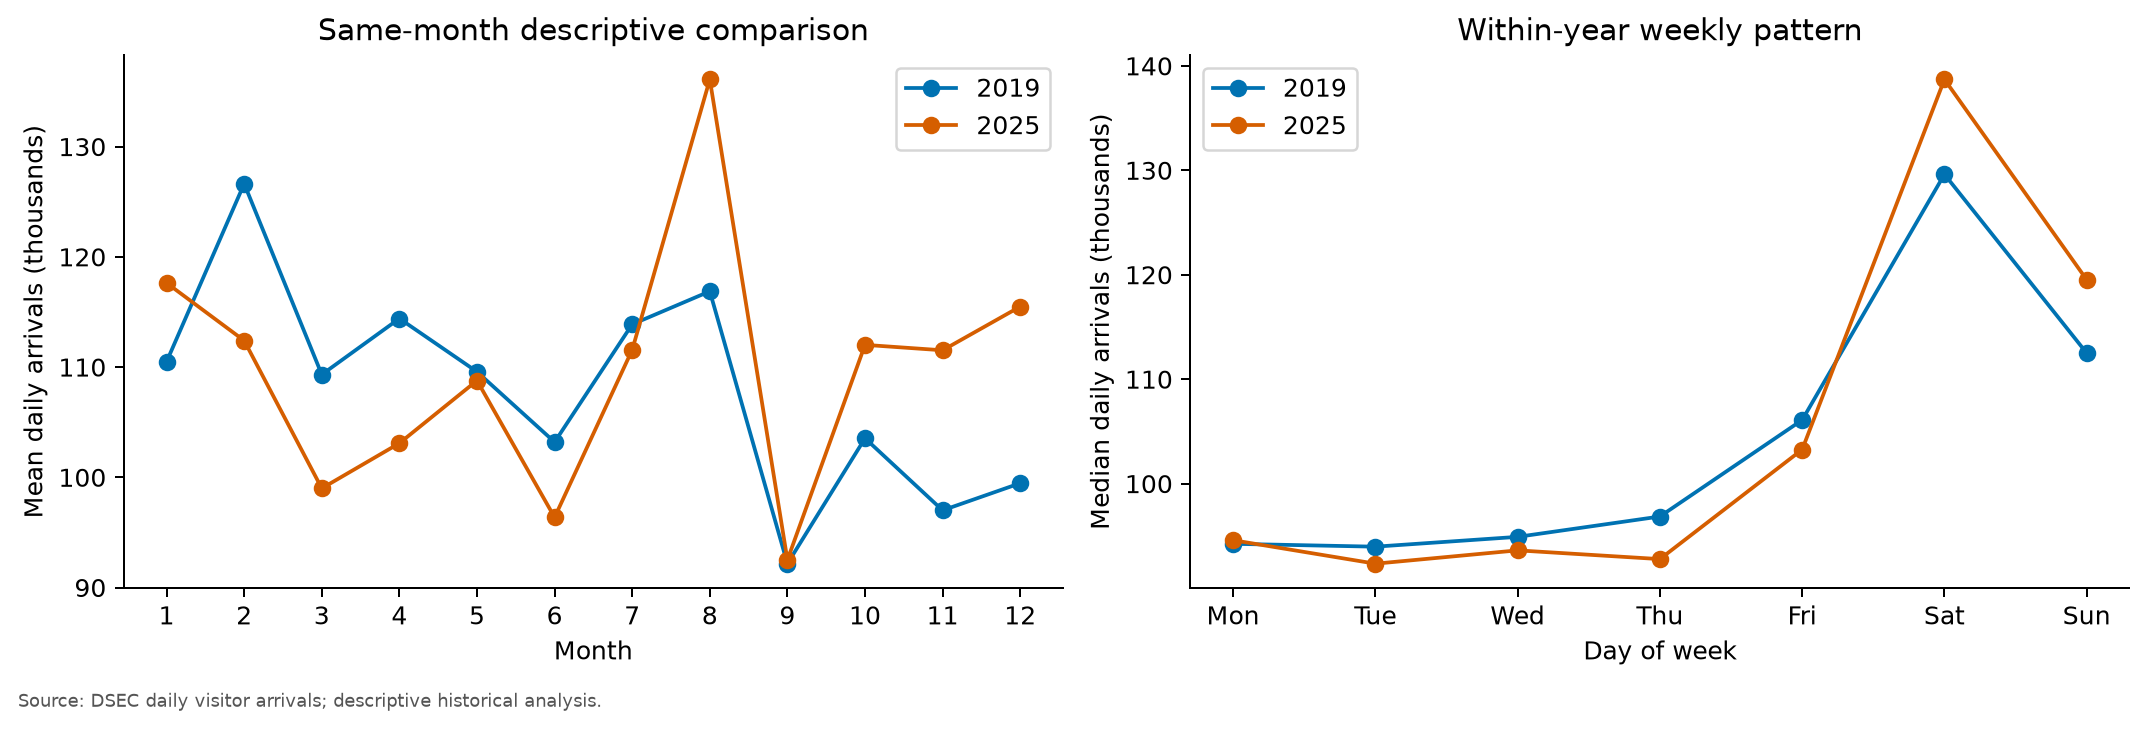

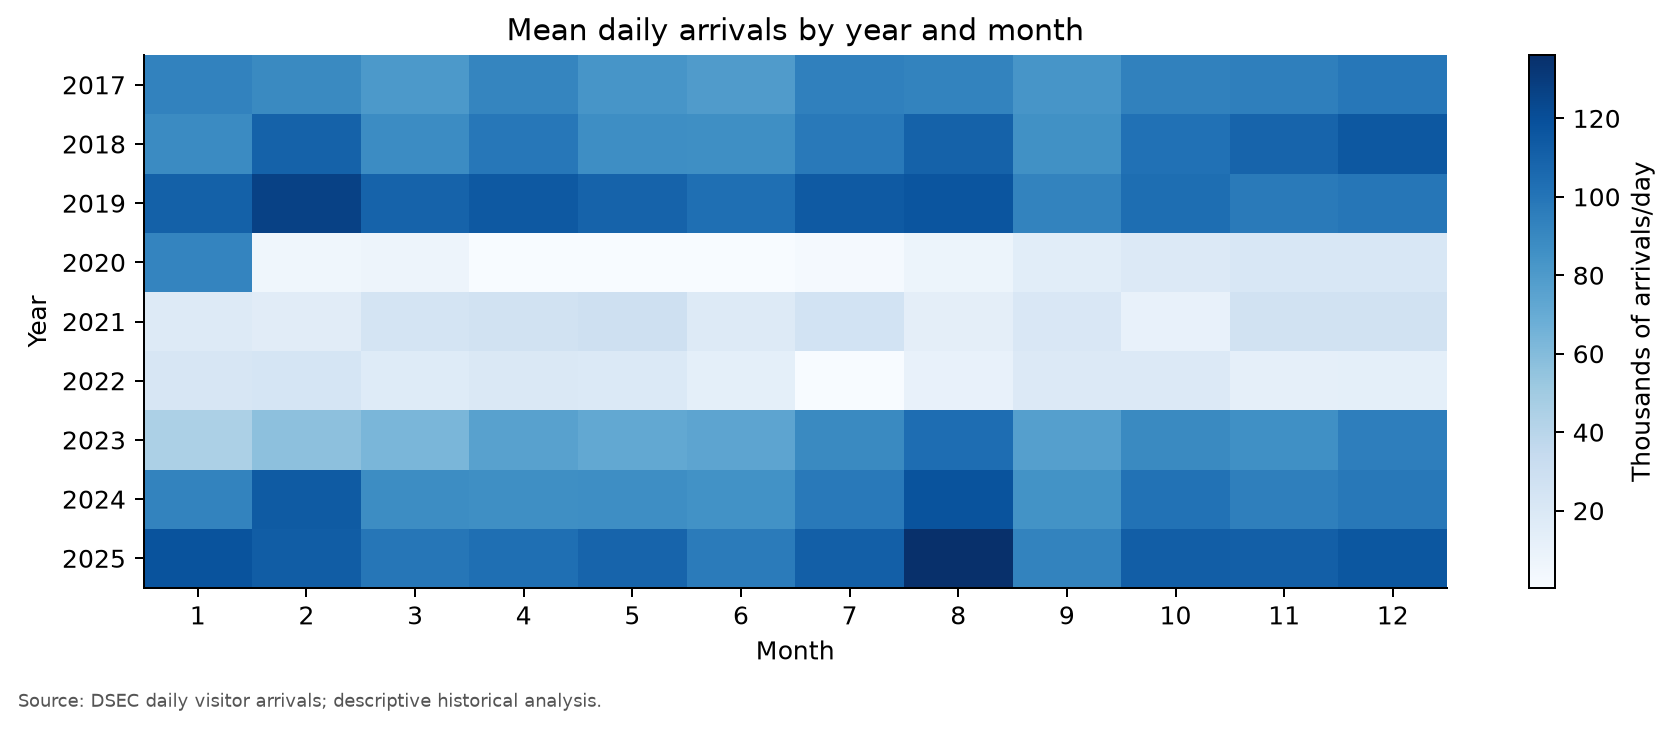

In [3]:
stages = group_describe(total, ["stage"])
annual = group_describe(total, ["year"])
comparison = total[total.year.isin([2019, 2025])].copy()
monthly = group_describe(comparison, ["year", "month"])
weekly = group_describe(comparison, ["year", "weekday"])
month_weekday = group_describe(comparison, ["year", "month", "weekday"])
for frame, name in [(stages, "stage_summary.csv"), (annual, "annual_summary.csv"),
                    (monthly, "month_comparison_2019_2025.csv"), (weekly, "weekday_comparison_2019_2025.csv"),
                    (month_weekday, "month_weekday_comparison_2019_2025.csv")]:
    save_table(frame, name)
print("Stage statistics:\n", stages.round(2).to_string(index=False))
print("Annual statistics:\n", annual.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(total.date, total.visitor_arrivals / 1000, lw=.55, color="#4C7899")
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-12-31"), color="#BBBBBB", alpha=.2)
ax.set(xlabel="Date", ylabel="Visitor arrivals (thousands/day)", title="Macao daily visitor arrivals, 2017-2025")
save_figure("01_daily_history.png")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ecdf_rows = []
shared_bins = np.arange(0, np.ceil(comparison.visitor_arrivals.max()/10000)*10+10, 10)
for year in [2019, 2025]:
    x = np.sort(comparison.loc[comparison.year.eq(year), "visitor_arrivals"].to_numpy())
    probability = np.arange(1, len(x)+1) / len(x)
    axes[0].step(x / 1000, probability, where="post", label=str(year), color=COLORS[year])
    axes[1].hist(x / 1000, bins=shared_bins, density=True, histtype="step", lw=1.6, label=str(year), color=COLORS[year])
    ecdf_rows.extend({"year": year, "arrivals": float(a), "ecdf": float(p)} for a,p in zip(x,probability))
axes[0].set(xlabel="Visitor arrivals (thousands/day)", ylabel="Fraction of days at or below x", title="Empirical CDF")
axes[1].set(xlabel="Visitor arrivals (thousands/day)", ylabel="Density per thousand arrivals", title="Same 10,000-arrival bins")
for ax in axes: ax.legend()
save_figure("02_ecdf_distribution_2019_2025.png")
save_table(pd.DataFrame(ecdf_rows), "ecdf_2019_2025.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for year in [2019, 2025]:
    m = monthly[monthly.year.eq(year)]
    w = weekly[weekly.year.eq(year)]
    axes[0].plot(m.month, m["mean"] / 1000, "o-", label=str(year), color=COLORS[year])
    axes[1].plot(w.weekday, w["median"] / 1000, "o-", label=str(year), color=COLORS[year])
axes[0].set(xlabel="Month", ylabel="Mean daily arrivals (thousands)", title="Same-month descriptive comparison", xticks=range(1,13))
axes[1].set(xlabel="Day of week", ylabel="Median daily arrivals (thousands)", title="Within-year weekly pattern", xticks=range(7), xticklabels=WEEKDAYS)
for ax in axes: ax.legend()
save_figure("03_month_weekday_comparison.png")

fig, ax = plt.subplots(figsize=(10,4))
heat = total.pivot_table(index="year", columns="month", values="visitor_arrivals", aggfunc="mean") / 1000
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="Blues")
ax.set(xticks=range(12), xticklabels=range(1,13), yticks=range(len(heat)), yticklabels=heat.index,
       xlabel="Month", ylabel="Year", title="Mean daily arrivals by year and month")
fig.colorbar(im, ax=ax, label="Thousands of arrivals/day")
save_figure("04_year_month_heatmap.png")

### Cell 3 interpretation: totals, typical dates and the upper tail differ

The [period summaries](results/stage_summary.csv), rounded for display, are:

| Period | Days | Daily mean | Daily median | IQR | P90 |
|---|---:|---:|---:|---:|---:|
| 2017–2019 | 1,095 | 98,466.07 | 94,448 | 25,660.5 | 127,003.2 |
| 2020–2022 | 1,096 | 17,612.34 | 17,218 | 14,530.5 | 28,366.0 |
| 2023–2025 | 1,096 | 94,170.63 | 89,783 | 33,341.5 | 130,763.5 |

A single full-period “average day” would hide large changes in context. The 2023–2025 median remains below that of 2017–2019, while its P90 is slightly higher and IQR wider. These describe observed distributions, not the causal effect of the pandemic or any policy.

The [annual table](results/annual_summary.csv) gives the direct 2019/2025 comparison:

| Measure | 2019 | 2025 |
|---|---:|---:|
| Annual arrivals | 39,406,181 | 40,069,360 |
| Daily mean | 107,962.14 | 109,779.07 |
| Daily median | 104,695 | 103,252 |
| Q25 | 90,853 | 90,614 |
| Q75 | 118,016 | 124,646 |
| IQR | 27,163 | 34,032 |
| P90 | 138,130.0 | 148,850.2 |
| Daily maximum | 226,326 | 221,857 |

Both years contain 365 days. Total arrivals rose by 663,179, or **1.68%**, but the median fell slightly while P90 and IQR increased. Recovery in total volume therefore differs from recovery on a typical date. This does not mean that every date improved. The 2025 maximum was lower, so a higher P90 does not mean that all peaks reached new records. Nor do these summaries establish that a few unusual dates explain all growth.

#### Reading the four figures

1. [Figure 1: daily history](figures/01_daily_history.png) shows changes over time. The grey band marks the fixed 2020–2022 period. Peaks and troughs remain in the data; the graph alone cannot assign weather or policy causes to them.
2. [Figure 2: ECDFs and density histograms](figures/02_ecdf_distribution_2019_2025.png) compares distributions. At the same x, a higher ECDF means that more dates are below that arrival level. At the same cumulative proportion, a curve further right has a higher quantile. The middle and upper portions explain how the median can fall while P90 rises. Histogram appearance depends on bin width; the ECDF supplies unbinned cumulative information.
3. [Figure 3: months and weekdays](figures/03_month_weekday_comparison.png) uses **monthly daily means** on the left and **weekday medians** on the right. August's mean rose from 116,874.71 to 136,097.87, while February's fell from 126,632.18 to 112,399.43. Saturday's median rose from 129,615 to 138,702 and Sunday's from 112,493 to 119,516. Tuesday fell from 93,965 to 92,336.5 and Thursday from 96,853 to 92,775. Changes differ across calendar groups.
4. [Figure 4: year × month heatmap](figures/04_year_month_heatmap.png) uses colour for the mean daily count. Colour is not a growth rate or a causal effect.

#### Conditioning on both month and weekday

The [month × weekday table](results/month_weekday_comparison_2019_2025.csv) compares the same weekday within the same month. This reduces mixing caused by comparing whole months or whole-year weekday groups. No separate figure is drawn for this table.

| Stratum | 2019 days | 2019 median | 2025 days | 2025 median |
|---|---:|---:|---:|---:|
| Saturdays in August | 5 | 143,876 | 5 | 179,215 |
| Tuesdays in February | 4 | 116,758 | 4 | 91,978 |

The two strata move in opposite directions. Each contains only four or five dates, and lunar holidays, weather and events are not aligned. These are conditional descriptions, not causal controls. The later regression does not include a month × weekday interaction.

This is direct volume evidence for RQ1 and the main distributional evidence for RQ2. Calendar patterns motivate RQ3 but do not establish predictive accuracy. RQ4 still requires the separate spending data.

## Code cell 4: source composition, net changes and overnight shares

### Purpose and steps

This cell asks which source groups increased or decreased, and how overnight/same-day composition changed. It sums arrivals by year and source group, then pivots 2019 and 2025 into paired columns. Three quantities must be kept distinct:

$$
s_{g,y}=\frac{N_{g,y}}{\sum_gN_{g,y}},\qquad
\Delta N_g=N_{g,2025}-N_{g,2019},\qquad
c_g=\frac{\Delta N_g}{\sum_g\Delta N_g}.
$$

$s_{g,y}$ is a group's share in a year, $\Delta N_g$ its absolute change, and $c_g$ its arithmetic contribution to the overall **net change**. A share change in percentage points is $100(s_{g,2025}-s_{g,2019})$. Negative and positive changes can offset, leaving a small net denominator, so contributions may be negative or above 100%. They are neither composition shares nor causal attribution.

For visitor types, daily shares are calculated, but annual composition uses the **ratio of annual totals**:

$$
\text{Annual overnight share}=\frac{\sum_d overnight_d}{\sum_d total_d}.
$$

This is not the simple mean of daily shares. The ratio answers what fraction of all arrivals during the year were overnight arrivals. Averaging daily shares weights quiet and busy dates equally and answers a different question.

The annual table retains raw and analysis same-day totals, flagged-day counts and raw missing-value counts. A separate `type_clean` branch excludes flagged dates and reports the resulting overnight-share difference in percentage points. The original data and main analysis retain every date. Figure 5 plots absolute source changes; Figure 6 plots annual type shares.

### Course links

Tutorial05-02, *Exploring Relationships between Two Variables*, pp3–10 covers conditional proportions and proportion differences; pp43–49 distinguishes association from causation. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848). Lecture04 pp57–67 covers categorical proportions; Lecture05 pp10–15 and 42–60 covers bars and composition; Tutorial04-01 pp30–42 covers derived variables and checks. See the [course directory](https://ummoodle.um.edu.mo/course/view.php?id=46674). This cell uses sums, ratios and differences, not Shapley, advanced index decomposition or causal attribution.

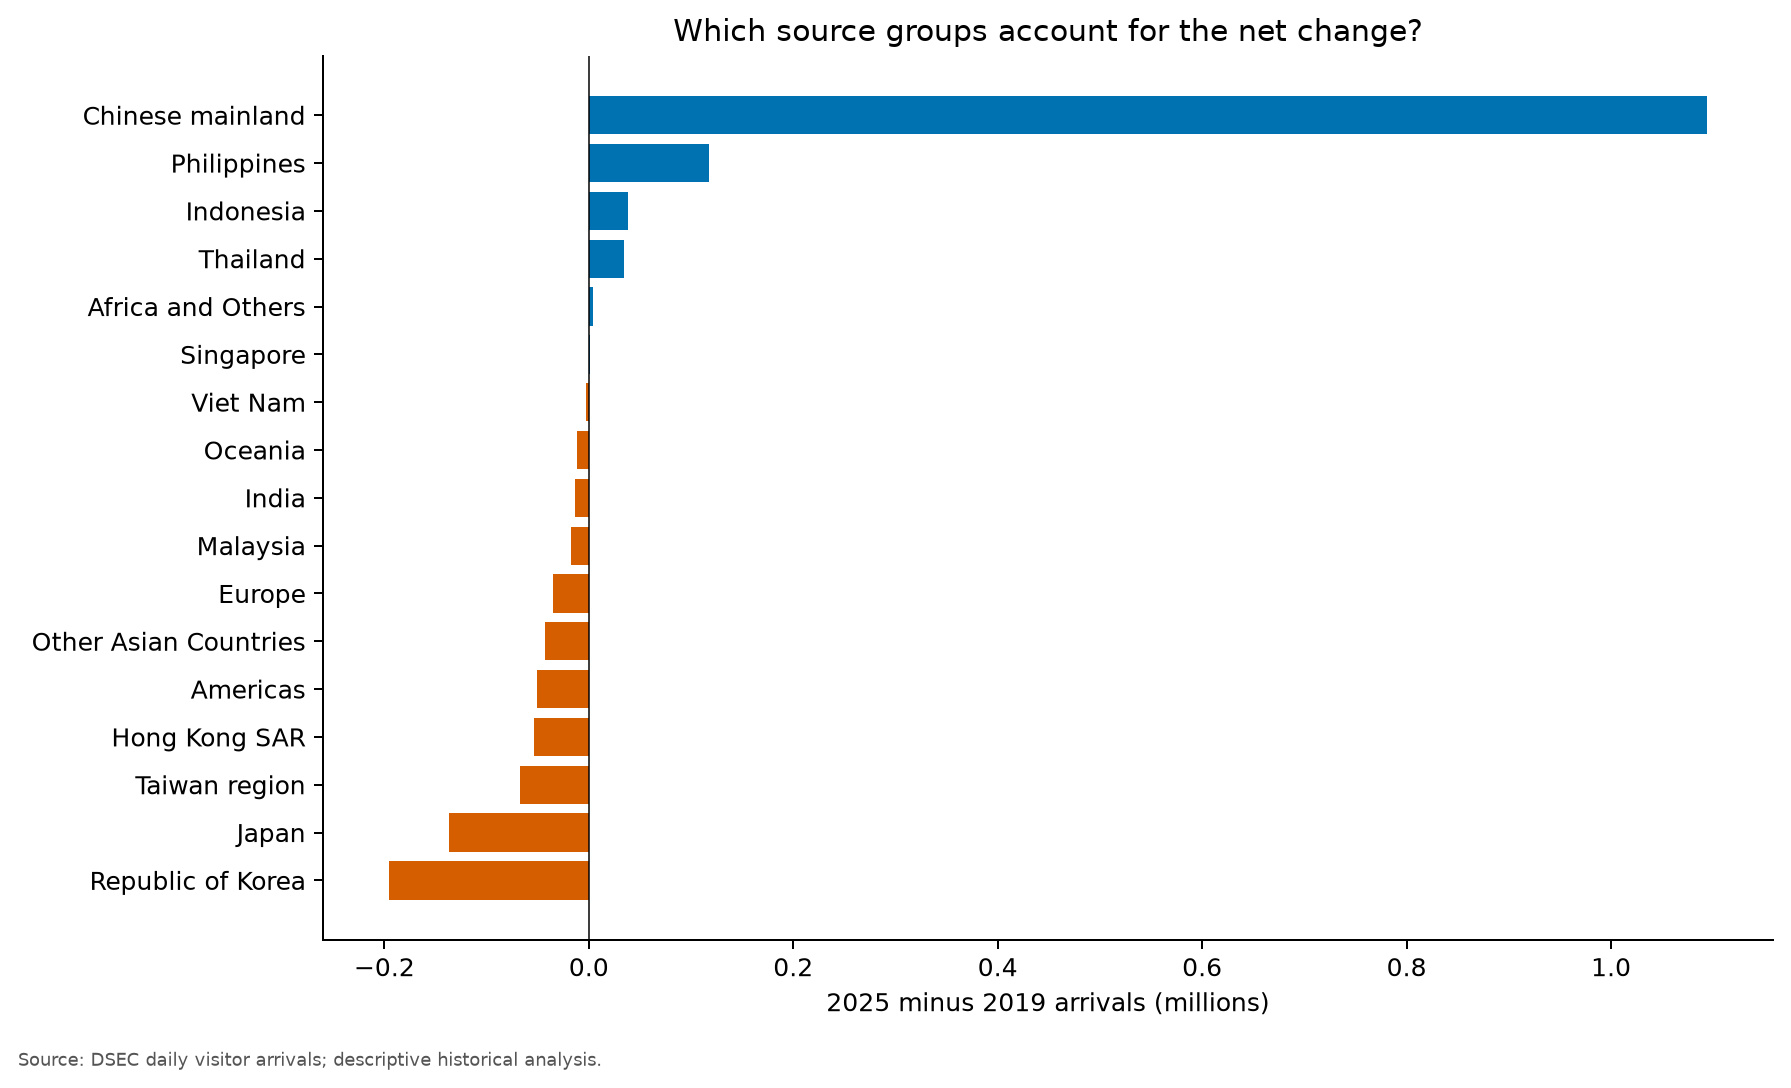

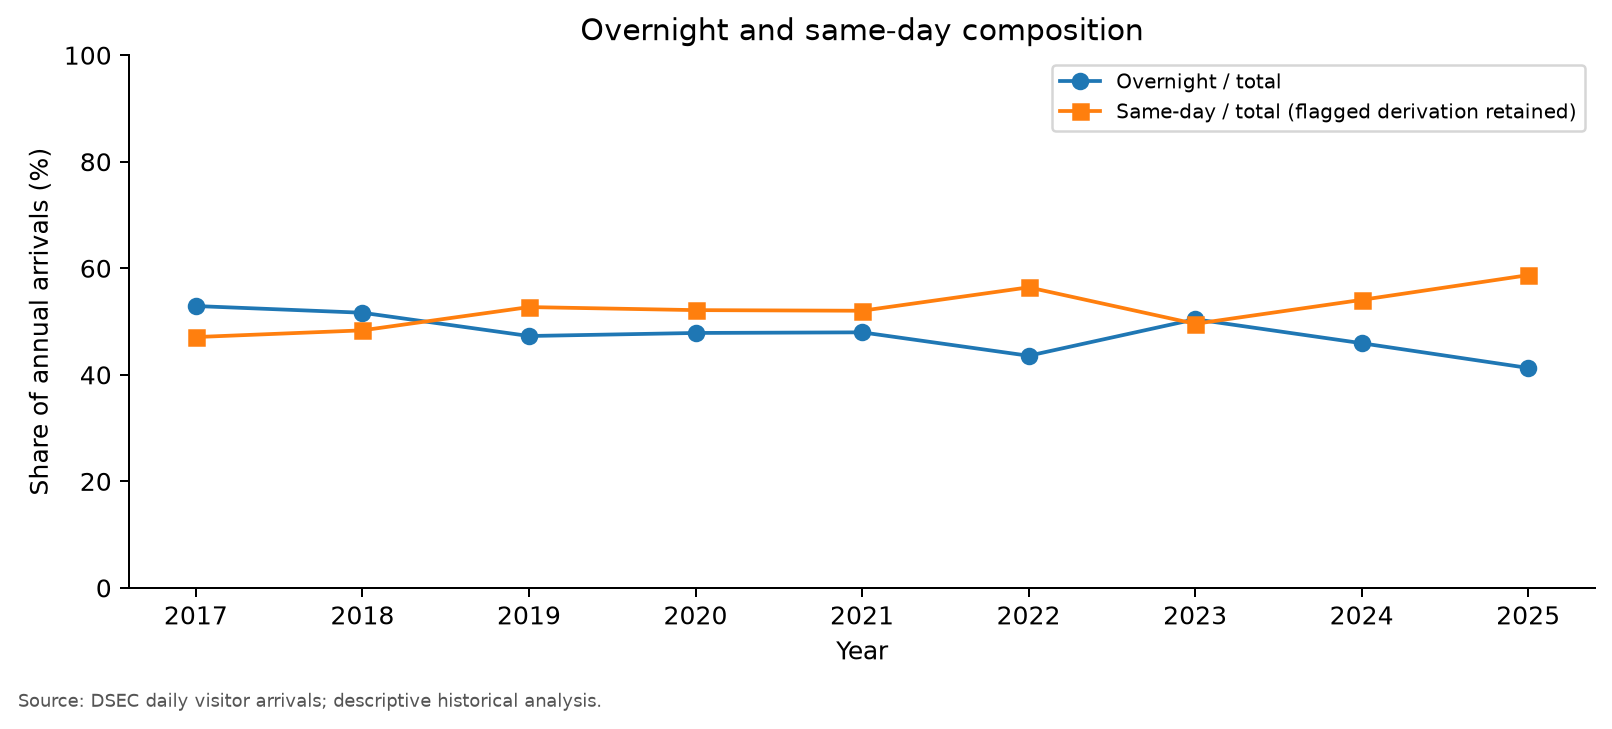

Source changes:
        source_name_en  change_arrivals  share_change_pp
    Republic of Korea          -195388        -0.518832
                Japan          -136328        -0.352653
        Taiwan region           -67215        -0.212408
        Hong Kong SAR           -53512        -0.442424
             Americas           -50286        -0.138745
Other Asian Countries           -43259        -0.112450
               Europe           -34918        -0.098813
             Malaysia           -17300        -0.051839
                India           -13311        -0.038569
              Oceania           -11514        -0.032951
             Viet Nam            -2978        -0.007694
            Singapore             1423        -0.001310
    Africa and Others             4114         0.009177
             Thailand            34442         0.079592
            Indonesia            38086         0.087912
          Philippines           117178         0.274667
     Chinese mainland          

In [4]:
sources["year"] = sources.date.dt.year
source_annual = sources.groupby(["year", "source_code", "source_name_zh", "source_name_en"], as_index=False).visitor_arrivals.sum()
source_annual["share"] = source_annual.visitor_arrivals / source_annual.groupby("year").visitor_arrivals.transform("sum")
save_table(source_annual, "source_annual_shares.csv")
source_change = source_annual.pivot(index=["source_code", "source_name_zh", "source_name_en"], columns="year", values="visitor_arrivals")[[2019,2025]].reset_index()
source_change.columns = ["source_code", "source_name_zh", "source_name_en", "arrivals_2019", "arrivals_2025"]
source_change["change_arrivals"] = source_change.arrivals_2025 - source_change.arrivals_2019
source_change["change_pct_within_source"] = source_change.arrivals_2025 / source_change.arrivals_2019 - 1
source_change["contribution_to_net_change"] = source_change.change_arrivals / source_change.change_arrivals.sum()
for year in [2019,2025]:
    source_change[f"share_{year}"] = source_change[f"arrivals_{year}"] / source_change[f"arrivals_{year}"].sum()
source_change["share_change_pp"] = 100*(source_change.share_2025-source_change.share_2019)
source_change = source_change.sort_values("change_arrivals")
save_table(source_change, "source_change_2019_2025.csv")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(source_change.source_name_en, source_change.change_arrivals / 1e6,
        color=np.where(source_change.change_arrivals.ge(0), "#0072B2", "#D55E00"))
ax.axvline(0, color="black", lw=.6)
ax.set(xlabel="2025 minus 2019 arrivals (millions)", title="Which source groups account for the net change?")
save_figure("05_source_contributions.png")

types["year"] = types.date.dt.year
types["overnight_share"] = types.overnight / types.total.replace(0,np.nan)
types["same_day_share_analysis"] = types.same_day_analysis / types.total.replace(0,np.nan)
type_annual = types.groupby("year").agg(total=("total","sum"), overnight=("overnight","sum"),
    same_day_raw_sum=("same_day_raw","sum"), same_day_analysis_sum=("same_day_analysis","sum"),
    flagged_days=("type_anomaly_flag","sum"), raw_missing=("same_day_raw", lambda x:x.isna().sum())).reset_index()
type_annual["overnight_share"] = type_annual.overnight / type_annual.total
type_annual["same_day_share_analysis"] = type_annual.same_day_analysis_sum / type_annual.total
type_clean = types[~types.type_anomaly_flag].groupby("year").agg(total=("total","sum"), overnight=("overnight","sum")).reset_index()
type_clean["overnight_share_excluding_flagged_days"] = type_clean.overnight / type_clean.total
type_annual = type_annual.merge(type_clean[["year","overnight_share_excluding_flagged_days"]], on="year")
type_annual["sensitivity_difference_pp"] = 100*(type_annual.overnight_share_excluding_flagged_days-type_annual.overnight_share)
save_table(type_annual, "type_annual_shares_and_sensitivity.csv")
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(type_annual.year, type_annual.overnight_share*100, "o-", label="Overnight / total")
ax.plot(type_annual.year, type_annual.same_day_share_analysis*100, "s-", label="Same-day / total (flagged derivation retained)")
ax.set(xlabel="Year", ylabel="Share of annual arrivals (%)", title="Overnight and same-day composition", ylim=(0,100))
ax.legend(fontsize=8)
save_figure("06_accommodation_shares.png")
print("Source changes:\n", source_change[["source_name_en","change_arrivals","share_change_pp"]].to_string(index=False))
print("Type shares:\n", type_annual.round(4).to_string(index=False))

### Cell 4 interpretation: shares and net changes answer different questions

The [source-change table](results/source_change_2019_2025.csv) shows Mainland China arrivals rising from 27,923,219 to 29,017,164, an increase of 1,093,945. Its share rose from 70.86% to 72.42%, about 1.56 percentage points. Its arithmetic contribution to the overall net increase of 663,179 is **164.95%**. This is valid arithmetic because decreases in other groups offset part of the increase.

| Source group | Change in arrivals, 2025 − 2019 | Interpretation |
|---|---:|---|
| Mainland China | +1,093,945 | Increase exceeds the overall net increase |
| Philippines | +117,178 | Absolute increase |
| Indonesia | +38,086 | Absolute increase |
| Thailand | +34,442 | Absolute increase |
| Hong Kong SAR | −53,512 | Absolute decrease |
| Japan | −136,328 | Absolute decrease |
| Republic of Korea | −195,388 | Absolute decrease |

[Figure 5](figures/05_source_contributions.png) plots **absolute changes** for all 17 groups, in millions of arrivals. Bars on opposite sides of zero show increases and decreases. Bar lengths are not 2025 market shares. The interpretation is an accounting comparison: Mainland China's increase exceeded the total net increase because other sources partly offset it. It does not show that a source “caused 164.95% of recovery”.

The [annual type and sensitivity table](results/type_annual_shares_and_sensitivity.csv) and [Figure 6](figures/06_accommodation_shares.png) show:

| Year | Total arrivals | Overnight arrivals | Overnight share | Same-day share, analysis field |
|---|---:|---:|---:|---:|
| 2019 | 39,406,181 | 18,632,699 | 47.28% | 52.72% |
| 2023 | 28,213,003 | 14,227,229 | 50.43% | 49.57% |
| 2024 | 34,928,650 | 16,043,768 | 45.93% | 54.07% |
| 2025 | 40,069,360 | 16,544,417 | 41.29% | 58.71% |

Despite slightly higher total arrivals in 2025, the overnight share fell by about **5.99 percentage points** from 2019. Percentage points describe the difference between shares, not percentage growth. The share also declined each year after 2023, but this pattern alone cannot identify a policy or preference as its cause.

#### Interpreting the flagged-date sensitivity check

Excluding flagged dates changes the annual overnight share by −0.0012 percentage points in 2018, −0.0114 in 2019, −0.0832 in 2021 and −0.2916 in 2022. There are no flagged dates in 2023–2025, so their differences are zero. These are the saved `sensitivity_difference_pp` values.

The main 2019/2025 comparison changes little under this exclusion rule. That does not establish that all quality concerns are absent. Exclusion removes real arrivals on entire dates: it changes the date set, rather than isolating the effect of correcting a ±1 discrepancy. In particular, the 2022 difference cannot be interpreted as the impact of one or two arrivals. The complete-date results remain primary.

This cell directly answers the composition part of RQ1 and supplies context for RQ2. Same-day type and source counts are excluded from RQ3 predictors because they add up to the target and would leak its value. Type changes motivate the RQ4 spending comparison, but **composition change alone does not establish the cause of spending change**.

## Code cell 5: calendar models and chronological validation

### Purpose and four candidates

For RQ3, we test whether calendar information improves on a simple baseline and how a trend and Ridge penalty affect performance. The target is the original `visitor_arrivals`, with no log transform or target standardization. Month, weekday and trend are available from the date. Same-day type and source counts are excluded because their additive relationship with the target would leak the answer.

| Candidate | Inputs and estimator | Purpose |
|---|---|---|
| `weekday_mean` | Training mean for each weekday | A simple reference for judging added complexity |
| `ols_calendar` | Month and weekday dummies, OLS | Additive month and weekday differences |
| `ols_calendar_trend` | The same dummies plus a continuous date trend, OLS | Allow a linear change in level over time |
| `ridge_calendar_trend` | The same features, Ridge | Penalize coefficient size and assess extrapolation stability |

OLS minimizes the training residual sum of squares. Ridge adds a squared-coefficient penalty:

$$
\min_{\beta_0,\boldsymbol{\beta}}
\sum_{d\in train}(y_d-\beta_0-\mathbf{x}_d^\top\boldsymbol{\beta})^2
+\alpha\sum_j\beta_j^2.
$$

The intercept is not penalized. Alpha is not a percentage, and there is no universal best value across datasets and feature scales. It is chosen within the specified validation design. Shrinkage does not guarantee that Ridge beats OLS in every test period.

### Exact encoding and scaling

`OneHotEncoder(drop="first")` treats month and weekday as categories rather than imposing a linear effect of month numbers 1–12. Every training window covers a full year. There are 11 month dummies and six weekday dummies, with January and Monday as reference categories. Dropping reference levels avoids exact redundancy with the intercept. Adding trend gives 18 features plus an intercept; there is no month × weekday interaction.

**`StandardScaler` transforms only `day_trend`; month and weekday dummies remain 0/1.** The trend is:

$$
t_d=(date_d-2023\text{-}01\text{-}01).days,\qquad
z_d=\frac{t_d-\mu_{train}}{\sigma_{train}}.
$$

This is elapsed time in days, not day-of-year resetting each January. The final 2023–2024 training range is 0–730 and the 2025 range is 731–1095. Predictions therefore extend beyond the training date range. Scaling changes units, not extrapolation risk. Each fold's `Pipeline` learns encoding and scaling only from that fold's training data. Ridge penalizes dummy and trend coefficients, but only trend is standardized, so alpha = 100 must be interpreted with this exact representation.

### Time splits and selection

`development` contains 731 dates in 2023–2024; `test` contains 365 dates in 2025. Each 2024 quarter is a validation fold, with training starting on 2023-01-01 and expanding through all earlier dates. Assertions ensure that training ends before validation starts. A previous validation quarter can enter the next training window because it is then in the past. This is not random cross-validation.

`GridSearchCV` searches alpha values `[0.01, 0.1, 1, 10, 100, 1000]` on these four folds. `neg_mean_squared_error` follows scikit-learn's higher-is-better scoring convention; the code reverses its sign to report MSE. The best-alpha Ridge is then compared with the other candidates on the same folds. Selection minimizes the **unweighted mean of four fold MSEs**, not the 2025 score:

$$
\overline{MSE}_{val}=\frac{1}{4}\sum_{k=1}^{4}MSE_k,\qquad
RMSE_{val}=\sqrt{\overline{MSE}_{val}}.
$$

Folds receive equal weight despite containing 91 or 92 dates. Validation RMSE is the square root of mean MSE, not the mean of four RMSEs. The selection is saved before the next cell scores the holdout.

### Course links

Multiple regression, Pipeline, MSE and R² appear in Assignment01 Module04 [material](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153103) and [cheatsheet](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153109). Train/test splitting, cross-validation, Ridge and GridSearchCV appear in Module05 [material](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153121), the [Ridge page](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153124) and [cheatsheet](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153127). These are webpages rather than slide-page references. Tutorial10-01 pp21–30 covers [standardization](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266950); Tutorial10-03 pp94–99 discusses the [dummy-variable trap](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266956). The expanding windows apply course validation principles to ordered dates; they are neither a claimed verbatim classroom split nor a specialized model such as ARIMA.

In [5]:
class WeekdayMean(RegressorMixin, BaseEstimator):
    def fit(self, X, y):
        self.means_ = pd.Series(np.asarray(y), index=np.asarray(X["weekday"])).groupby(level=0).mean()
        self.global_mean_ = float(np.mean(y))
        return self
    def predict(self, X):
        return X["weekday"].map(self.means_).fillna(self.global_mean_).to_numpy()

def calendar_pipeline(estimator, trend=False):
    transformers = [("calendar", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="error"), ["month", "weekday"])]
    if trend:
        transformers.append(("trend", StandardScaler(), ["day_trend"]))
    return Pipeline([("features", ColumnTransformer(transformers, remainder="drop")), ("model", estimator)])

model_data = total[total.year.ge(2023)].copy().reset_index(drop=True)
model_data["day_trend"] = (model_data.date-pd.Timestamp("2023-01-01")).dt.days
development = model_data[model_data.year.le(2024)].reset_index(drop=True)
test = model_data[model_data.year.eq(2025)].reset_index(drop=True)
assert len(development) == 731 and len(test) == 365
features = ["month", "weekday", "day_trend"]
Xdev, ydev = development[features], development.visitor_arrivals
Xtest, ytest = test[features], test.visitor_arrivals
folds, split_rows = [], []
for quarter, (start, end) in enumerate([("2024-01-01","2024-04-01"),("2024-04-01","2024-07-01"),
                                       ("2024-07-01","2024-10-01"),("2024-10-01","2025-01-01")], 1):
    tr = np.flatnonzero(development.date.lt(start))
    va = np.flatnonzero(development.date.ge(start)&development.date.lt(end))
    assert development.date.iloc[tr].max() < development.date.iloc[va].min()
    folds.append((tr, va))
    split_rows.append({"fold":quarter,"train_start":development.date.iloc[tr[0]],"train_end":development.date.iloc[tr[-1]],
                       "train_n":len(tr),"valid_start":development.date.iloc[va[0]],"valid_end":development.date.iloc[va[-1]],"valid_n":len(va)})
save_table(pd.DataFrame(split_rows), "chronological_folds.csv")
print("Chronological validation:\n", pd.DataFrame(split_rows).to_string(index=False))

alphas = [.01,.1,1,10,100,1000]
grid = GridSearchCV(calendar_pipeline(Ridge(), True), {"model__alpha":alphas}, scoring="neg_mean_squared_error", cv=folds, refit=True, n_jobs=1, return_train_score=True)
grid.fit(Xdev,ydev)
ridge_cv = pd.DataFrame({"alpha":[p["model__alpha"] for p in grid.cv_results_["params"]],
                        "mean_validation_mse":-grid.cv_results_["mean_test_score"],
                        "std_fold_mse":grid.cv_results_["std_test_score"]})
for i in range(4): ridge_cv[f"fold_{i+1}_mse"] = -grid.cv_results_[f"split{i}_test_score"]
save_table(ridge_cv,"ridge_alpha_validation.csv")
models = {"weekday_mean":WeekdayMean(), "ols_calendar":calendar_pipeline(LinearRegression()),
          "ols_calendar_trend":calendar_pipeline(LinearRegression(),True), "ridge_calendar_trend":clone(grid.best_estimator_)}
validation_rows = []
for name, estimator in models.items():
    result = cross_validate(estimator, Xdev,ydev,cv=folds,scoring="neg_mean_squared_error",n_jobs=1)
    errors = -result["test_score"]
    row = {"model":name,"validation_mse":float(errors.mean()),"validation_rmse":float(np.sqrt(errors.mean()))}
    row.update({f"fold_{i+1}_mse":float(v) for i,v in enumerate(errors)})
    validation_rows.append(row)
validation = pd.DataFrame(validation_rows).sort_values("validation_mse")
selected_name = validation.iloc[0].model
model_labels = {"weekday_mean": "Weekday mean", "ols_calendar": "OLS calendar",
                "ols_calendar_trend": "OLS calendar + trend", "ridge_calendar_trend": "Ridge calendar + trend"}
selected_label = model_labels[selected_name]
selection = {"selected_model":selected_name,"selected_ridge_alpha":float(grid.best_params_["model__alpha"]),
             "selection_rule":"Lowest unweighted mean of four chronological 2024-quarter validation MSEs; no 2025 information."}
# This selection file is deliberately written before evaluating any 2025 target.
(RESULTS/"model_selection_before_test.json").write_text(json.dumps(selection,indent=2),encoding="utf-8")
save_table(validation,"model_validation.csv")
print("Validation selection:\n",validation.round(2).to_string(index=False))
print(selection)

Chronological validation:
  fold train_start  train_end  train_n valid_start  valid_end  valid_n
    1  2023-01-01 2023-12-31      365  2024-01-01 2024-03-31       91
    2  2023-01-01 2024-03-31      456  2024-04-01 2024-06-30       91
    3  2023-01-01 2024-06-30      547  2024-07-01 2024-09-30       92
    4  2023-01-01 2024-09-30      639  2024-10-01 2024-12-31       92


Validation selection:
                model  validation_mse  validation_rmse   fold_1_mse   fold_2_mse   fold_3_mse   fold_4_mse
ridge_calendar_trend    6.160733e+08         24820.82 8.580826e+08 7.499781e+08 366465144.00 489767096.90
        weekday_mean    6.829380e+08         26133.08 1.208080e+09 3.419615e+08 664425634.82 517285032.60
        ols_calendar    9.533507e+08         30876.38 2.658128e+09 4.799495e+08 267504537.20 407820356.80
  ols_calendar_trend    5.439560e+09         73753.37 1.951745e+10 1.246426e+09 459351002.33 535009554.86
{'selected_model': 'ridge_calendar_trend', 'selected_ridge_alpha': 100.0, 'selection_rule': 'Lowest unweighted mean of four chronological 2024-quarter validation MSEs; no 2025 information.'}


### Cell 5 interpretation: alpha = 100 is selected on 2024 validation

The [split table](results/chronological_folds.csv) confirms:

| Fold | Training dates | Training days | Validation dates | Validation days |
|---|---|---:|---|---:|
| 1 | 2023-01-01 to 2023-12-31 | 365 | 2024-01-01 to 2024-03-31 | 91 |
| 2 | 2023-01-01 to 2024-03-31 | 456 | 2024-04-01 to 2024-06-30 | 91 |
| 3 | 2023-01-01 to 2024-06-30 | 547 | 2024-07-01 to 2024-09-30 | 92 |
| 4 | 2023-01-01 to 2024-09-30 | 639 | 2024-10-01 to 2024-12-31 | 92 |

The [Ridge search results](results/ridge_alpha_validation.csv) are:

| Alpha | Mean validation MSE, squared arrivals, rounded |
|---:|---:|
| 0.01 | 4,355,475,955 |
| 0.1 | 1,784,127,193 |
| 1 | 932,328,597 |
| 10 | 744,627,715 |
| 100 | 616,073,252 |
| 1000 | 641,079,090 |

Alpha 100 is best **within this discrete grid and validation design**, not a proven global optimum over continuous alpha values. Raising alpha to 1000 does not improve the score. The [candidate comparison](results/model_validation.csv) is:

| Candidate | Mean validation MSE | Validation RMSE, arrivals/day |
|---|---:|---:|
| Ridge calendar + trend | 616,073,251.60 | 24,820.82 |
| Weekday mean | 682,938,043.90 | 26,133.08 |
| OLS calendar | 953,350,710.04 | 30,876.38 |
| OLS calendar + trend | 5,439,560,159.51 | 73,753.37 |

The selected candidate, `ridge_calendar_trend` with alpha = 100, is written to the [selection record](results/model_selection_before_test.json). Ridge does not win every fold: in fold 4, calendar-only OLS has MSE 407,820,356.80 versus Ridge's 489,767,096.90. Selection follows the predefined average score rather than a favourable individual fold.

#### Why OLS with trend has a large validation score

Its first-fold MSE is 19,517,454,547.30, compared with 1,246,425,533.56, 459,351,002.33 and 535,009,554.86 in the next three folds. The first fold drives the high average. With only one full training year, separating month effects from trend may be difficult and extrapolation may be unstable. This is a **possible explanation**, not a completed diagnosis: fold-specific coefficients, condition numbers and predictions were not saved, so the experiment has not demonstrated multicollinearity as the cause.

Alpha search and candidate comparison reuse the same four folds; no nested validation was performed. These validation scores support selection and are not unbiased post-selection performance estimates. The next cell evaluates 2025. Excluding 2025 from the selection calculation is distinct from never having examined it: the descriptive analysis already showed 2025.

This cell establishes the RQ3 selection procedure. The patterns in RQ1/RQ2 motivate calendar modelling but cannot replace validation. RQ4 spending values are not used in training or tuning. No holidays, lags or contemporaneous composition variables were added after inspecting model scores.

## Code cell 6: the 2025 holdout and conditional errors

### Purpose and steps

After selection, every candidate is refitted on all 731 dates in 2023–2024 and evaluated on all of 2025. All candidate test results are reported, but test ranking does not change the selection. This is historical holdout evaluation, not a deployed real-time forecast. DSEC publication latency is unknown, so immediate historical data availability is not assumed.

Daily residuals are actual minus predicted: $e_d=y_d-\widehat y_d$. Positive residuals mean underestimation; negative residuals mean overestimation. Metrics are:

$$
MSE=\frac{1}{n}\sum_de_d^2,\qquad
RMSE=\sqrt{MSE},\qquad
MAE=\frac{1}{n}\sum_d|e_d|,
$$

$$
R^2=1-\frac{\sum_de_d^2}{\sum_d(y_d-\bar y_{test})^2},\qquad
\text{Mean residual}=\frac{1}{n}\sum_de_d.
$$

MSE has squared-arrival units and gives greater weight to large errors. RMSE returns to arrivals/day; it does not mean every day has that error. MAE is the mean absolute error. R² compares squared error with the test period's actual mean. It is not an accuracy percentage or a causal explanation. A negative value means the model has greater squared error than that retrospective constant-mean reference, which was not known to the model in advance.

For each candidate, the code saves 365 predictions and residuals. It summarizes RMSE, MAE and mean residual by month, weekday and a high-arrival flag. The threshold is calculated only from the final 2023–2024 training set and then fixed:

$$
H_d=\mathbf{1}(y_d>Q_{0.90}(y_{2023\text{–}2024})).
$$

Grouping uses **actual** 2025 arrivals. It is a retrospective error diagnostic, not a claim that high-arrival dates can be identified in advance. P90 is a statistical threshold, not an official capacity or risk limit. Negative predictions are counted, not clipped to zero.

Figures 7–10 show actual/predicted series and residuals over time; residuals versus predictions and errors by calendar group; validation/holdout errors; and errors above/below the fixed P90 threshold.

### Course links

Tutorial05-02 pp31–38 covers residuals, OLS and R²; pp39–42 covers extrapolation. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848). Tutorial10-02, *Estimation*, pp5–10 discusses MSE/RMSE and loss. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266953). Assignment01 Module04 includes [evaluation and diagnostics](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153103). Lecture10, *Data and Sampling Distributions*, pp18–25 covers data snooping and holdouts. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266908). Practice08 also asks students to interpret train/test R², MSE and residual changes; see the [course directory](https://ummoodle.um.edu.mo/course/view.php?id=46674).

**Role of MAE:** It applies the course concepts of a mean (Lecture04 p20) and residuals (Tutorial05-02 pp31–38) as an additional descriptive summary. We did not find evidence that Module05 explicitly teaches MAE, so it is not presented as a separate taught algorithm or used for selection; 2024 validation MSE remains the selection criterion. MAE around date-specific predictions is also not the same as MAD around a sample mean.

Final historical holdout:
                model          mse      rmse       mae     r2  bias_observed_minus_predicted  negative_predictions  selected_from_validation  validation_mse  validation_rmse
        weekday_mean 1.144605e+09 33832.004 25585.713 -0.349                      23414.880                     0                     False    6.829380e+08        26133.083
        ols_calendar 1.103500e+09 33218.972 25113.425 -0.301                      23414.559                     0                     False    9.533507e+08        30876.378
  ols_calendar_trend 5.719844e+08 23916.195 16728.148  0.326                      -4061.908                     0                     False    5.439560e+09        73753.374
ridge_calendar_trend 6.666089e+08 25818.770 18767.154  0.214                      -2458.973                     0                      True    6.160733e+08        24820.823
Training P90 high-arrival threshold: 121707.0


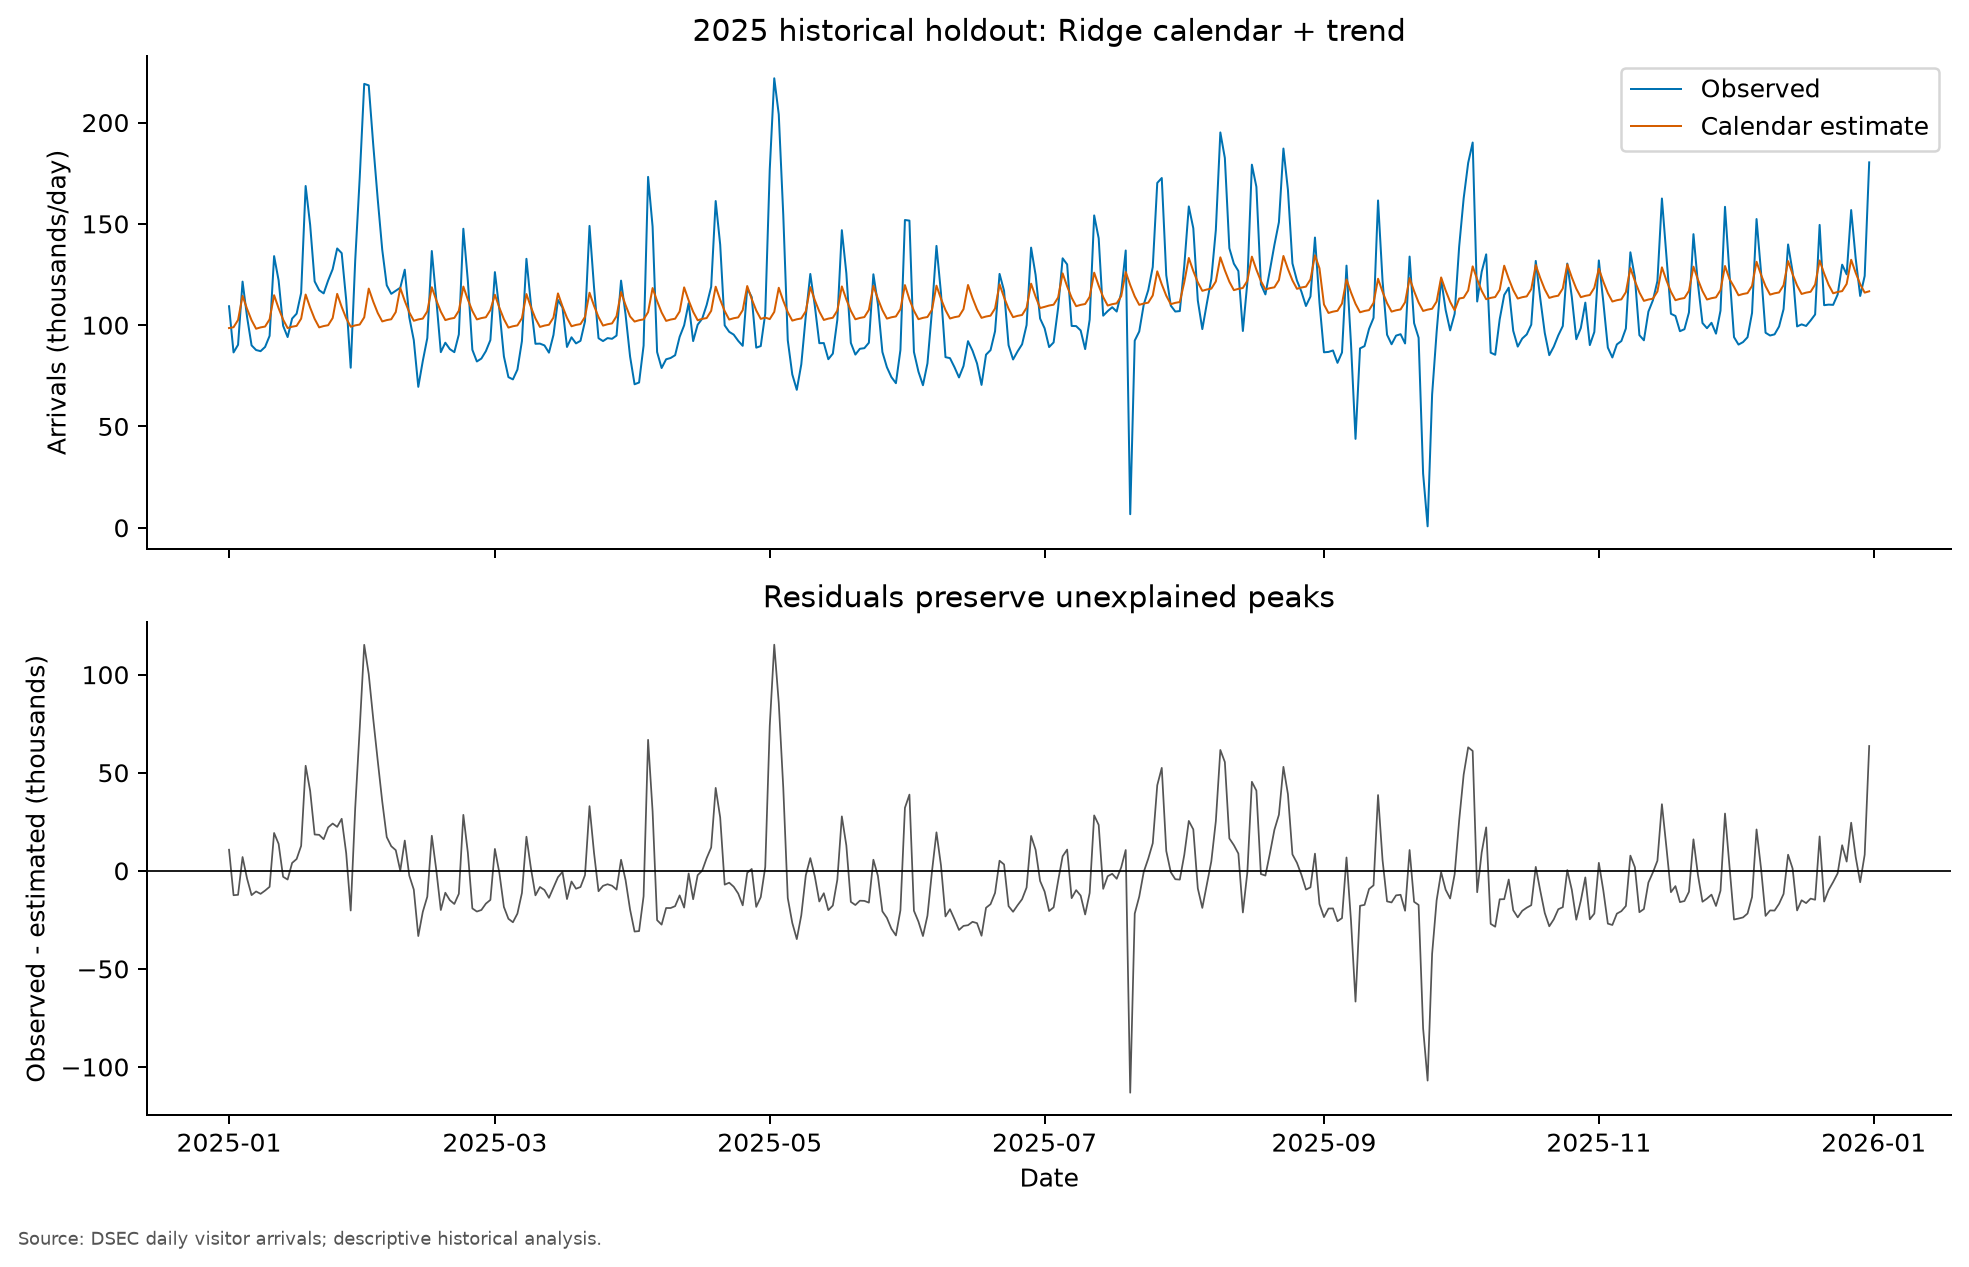

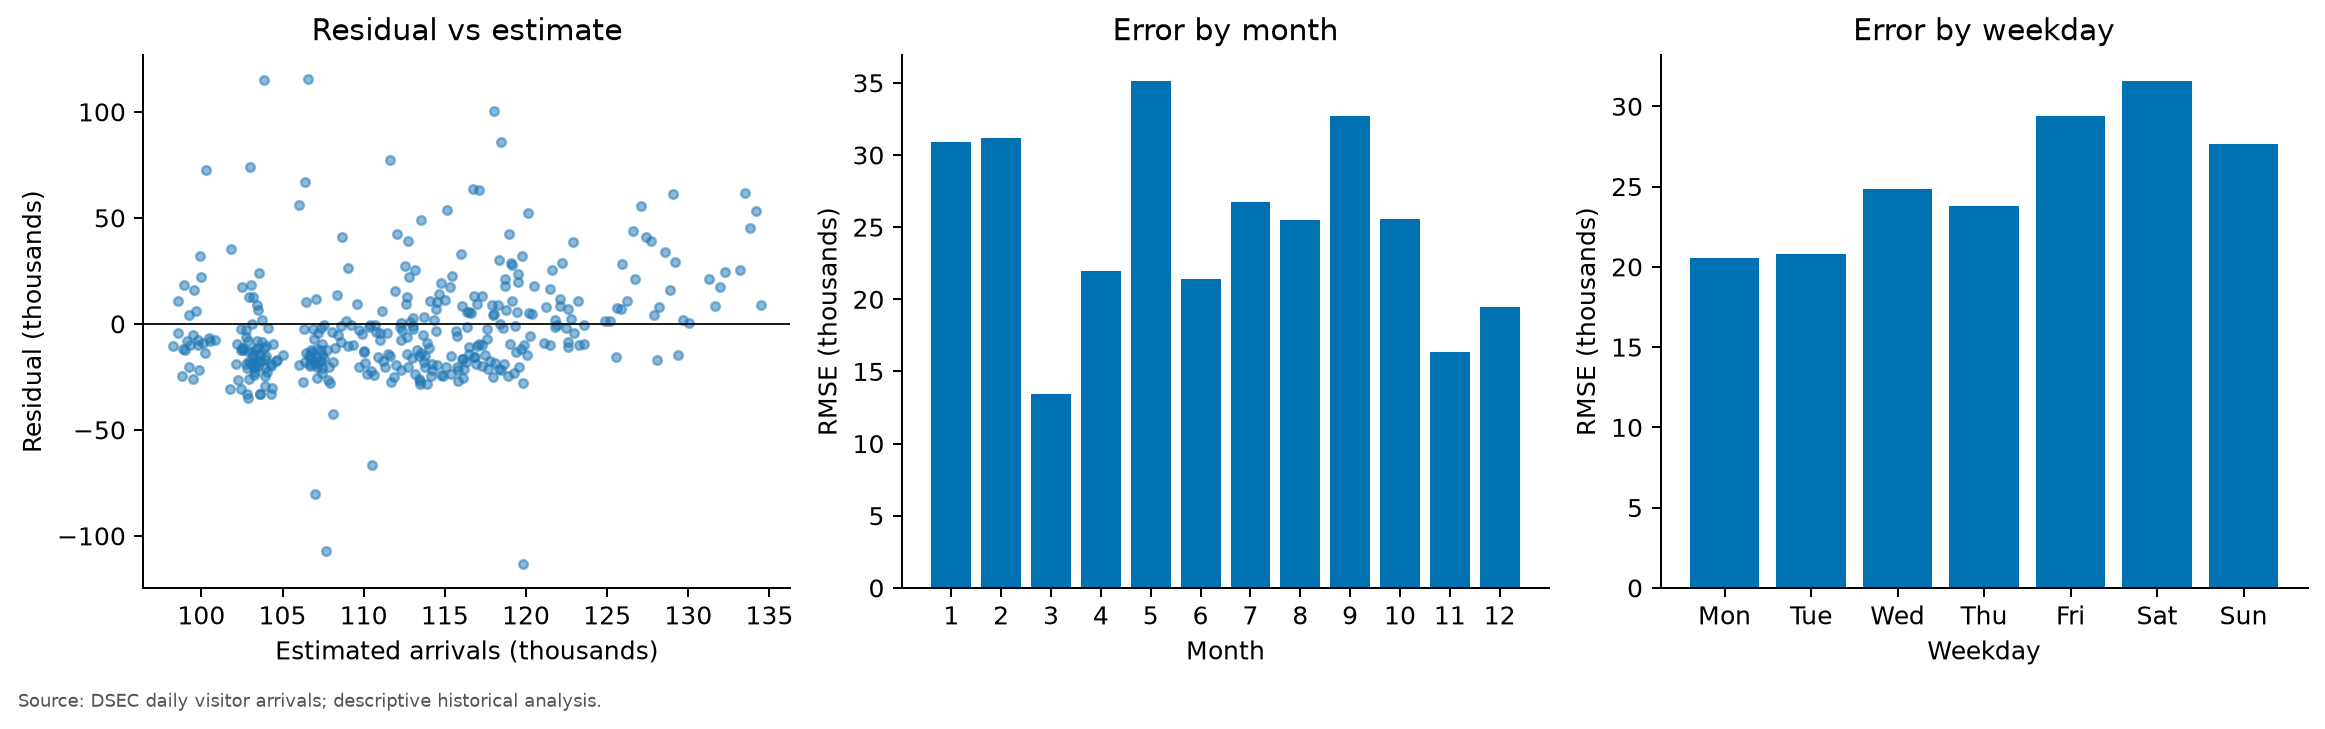

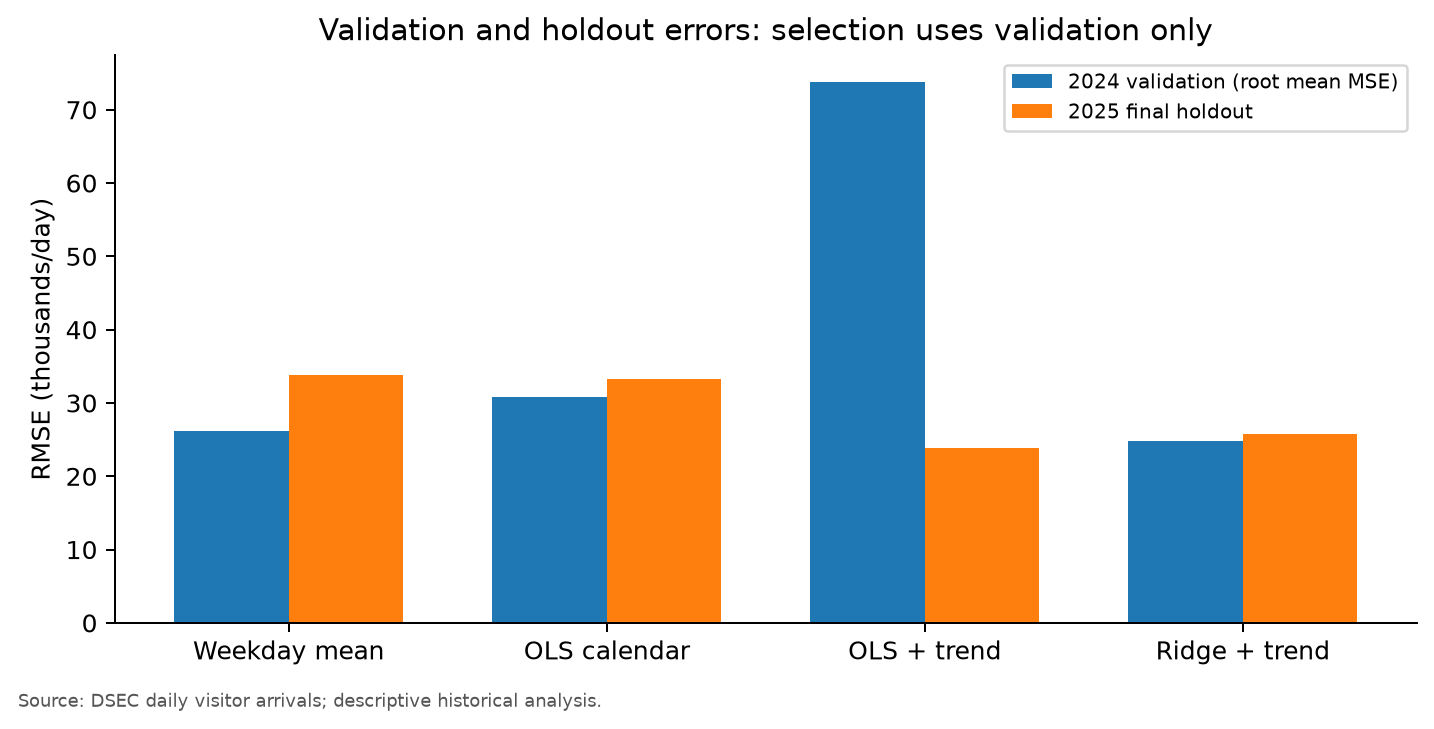

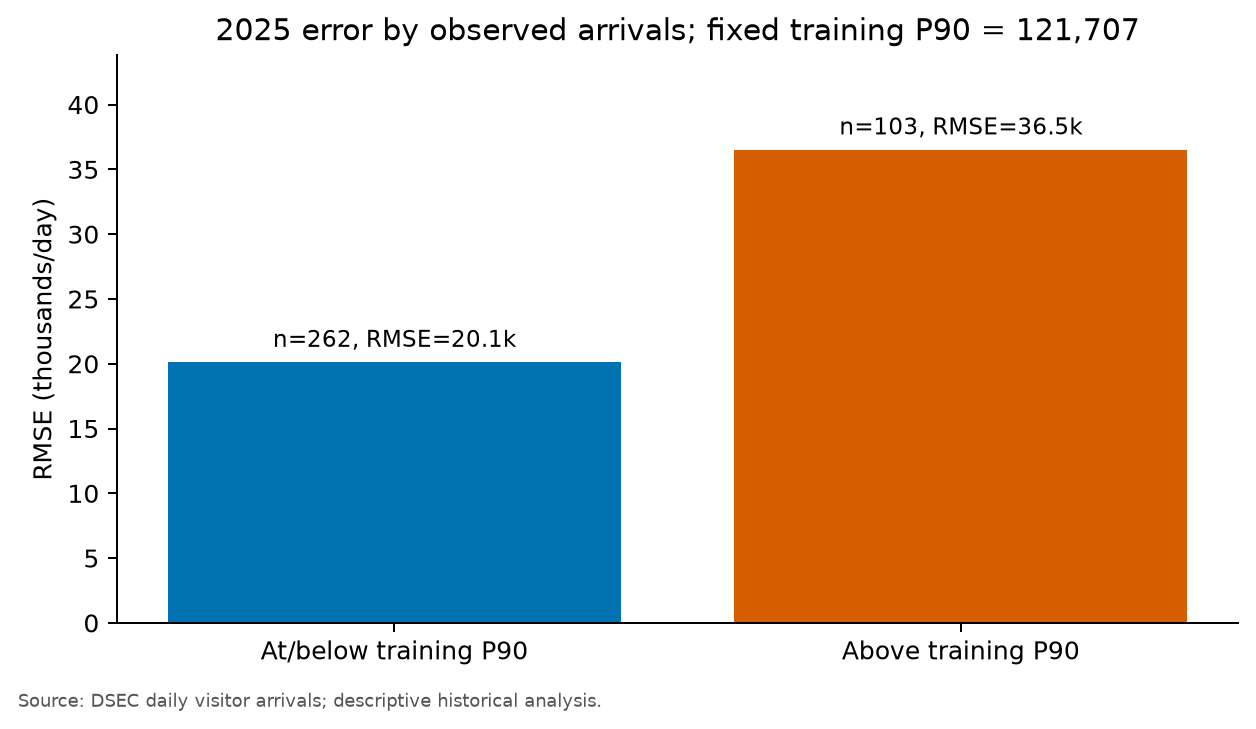

Selected-model high-arrival diagnostic:
                       model                 group_type  days      rmse       mae  bias_observed_minus_predicted  mean_observed
group                                                                                                                         
False  ridge_calendar_trend  high_arrival_training_p90   262  20115.40  15504.19                      -14061.04       95462.45
True   ridge_calendar_trend  high_arrival_training_p90   103  36510.33  27067.13                       27053.09      146196.10


In [6]:
test_rows, prediction_rows, diagnostic_rows = [], [], []
high_threshold = float(ydev.quantile(.9))
for name, estimator in models.items():
    estimator.fit(Xdev,ydev)
    pred = estimator.predict(Xtest)
    mse = mean_squared_error(ytest,pred)
    test_rows.append({"model":name,"mse":mse,"rmse":np.sqrt(mse),"mae":mean_absolute_error(ytest,pred),
                      "r2":r2_score(ytest,pred),"bias_observed_minus_predicted":float(np.mean(ytest-pred)),
                      "negative_predictions":int((pred<0).sum()),"selected_from_validation":name==selected_name})
    part = test[["date","month","weekday","visitor_arrivals"]].copy()
    part["model"], part["prediction"], part["residual"] = name, pred, ytest-pred
    part["high_arrival_training_p90"] = part.visitor_arrivals.gt(high_threshold)
    prediction_rows.append(part)
    for key in ["month","weekday","high_arrival_training_p90"]:
        for value, g in part.groupby(key):
            diagnostic_rows.append({"model":name,"group_type":key,"group":str(value),"days":len(g),
                "rmse":float(np.sqrt(np.mean(g.residual**2))),"mae":float(np.mean(np.abs(g.residual))),
                "bias_observed_minus_predicted":float(g.residual.mean()),"mean_observed":float(g.visitor_arrivals.mean())})
scores = pd.DataFrame(test_rows).merge(validation[["model","validation_mse","validation_rmse"]],on="model")
predictions = pd.concat(prediction_rows,ignore_index=True)
diagnostics = pd.DataFrame(diagnostic_rows)
save_table(scores,"model_test_metrics.csv")
save_table(predictions,"test_predictions.csv")
save_table(diagnostics,"test_error_diagnostics.csv")
print("Final historical holdout:\n",scores.round(3).to_string(index=False))
print("Training P90 high-arrival threshold:",high_threshold)
chosen = predictions[predictions.model.eq(selected_name)].copy()

fig, axes = plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].plot(chosen.date,chosen.visitor_arrivals/1000,lw=.8,label="Observed",color="#0072B2")
axes[0].plot(chosen.date,chosen.prediction/1000,lw=.8,label="Calendar estimate",color="#D55E00")
axes[0].set(ylabel="Arrivals (thousands/day)",title=f"2025 historical holdout: {selected_label}")
axes[0].legend()
axes[1].plot(chosen.date,chosen.residual/1000,lw=.7,color="#555555")
axes[1].axhline(0,color="black",lw=.7)
axes[1].set(xlabel="Date",ylabel="Observed - estimated (thousands)",title="Residuals preserve unexplained peaks")
save_figure("07_holdout_predictions_residuals.png")

fig, axes = plt.subplots(1,3,figsize=(13,4))
axes[0].scatter(chosen.prediction/1000,chosen.residual/1000,s=12,alpha=.5)
axes[0].axhline(0,color="black",lw=.7)
axes[0].set(xlabel="Estimated arrivals (thousands)",ylabel="Residual (thousands)",title="Residual vs estimate")
for ax,key,title in [(axes[1],"month","Error by month"),(axes[2],"weekday","Error by weekday")]:
    g=diagnostics[(diagnostics.model.eq(selected_name))&diagnostics.group_type.eq(key)].copy()
    g["order"]=g.group.astype(int);g=g.sort_values("order")
    ax.bar(g.order,g.rmse/1000,color="#0072B2")
    ax.set(xlabel="Month" if key=="month" else "Weekday",ylabel="RMSE (thousands)",title=title)
    ax.set_xticks(g.order, g.order if key=="month" else WEEKDAYS)
save_figure("08_holdout_error_diagnostics.png")

fig, ax=plt.subplots(figsize=(8,4))
positions=np.arange(len(scores));width=.36
ax.bar(positions-width/2,scores.validation_rmse/1000,width,label="2024 validation (root mean MSE)")
ax.bar(positions+width/2,scores.rmse/1000,width,label="2025 final holdout")
ax.set(xticks=positions,xticklabels=["Weekday mean","OLS calendar","OLS + trend","Ridge + trend"],ylabel="RMSE (thousands/day)",title="Validation and holdout errors: selection uses validation only")
ax.legend(fontsize=8)
save_figure("09_model_comparison.png")

high_diagnostic = diagnostics[(diagnostics.model.eq(selected_name)) &
                             diagnostics.group_type.eq("high_arrival_training_p90")].copy()
high_diagnostic = high_diagnostic.set_index("group").reindex(["False", "True"])
fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(["At/below training P90", "Above training P90"], high_diagnostic.rmse/1000,
              color=["#0072B2", "#D55E00"])
ax.bar_label(bars, labels=[f"n={int(n)}, RMSE={r/1000:.1f}k" for n,r in
                          zip(high_diagnostic.days, high_diagnostic.rmse)], padding=4, fontsize=9)
ax.set(ylabel="RMSE (thousands/day)", ylim=(0, high_diagnostic.rmse.max()/1000*1.2),
       title=f"2025 error by observed arrivals; fixed training P90 = {high_threshold:,.0f}")
save_figure("10_high_arrival_error.png")
print("Selected-model high-arrival diagnostic:\n", high_diagnostic.round(2).to_string())

### Cell 6 interpretation: validation and test rankings differ

The [test metrics](results/model_test_metrics.csv) are below. RMSE, MAE and mean residual use arrivals/day.

| Model | 2024 validation RMSE | 2025 test RMSE | 2025 test MAE | 2025 R² | Mean residual, actual − predicted |
|---|---:|---:|---:|---:|---:|
| Weekday mean | 26,133.08 | 33,832.00 | 25,585.71 | −0.3491 | +23,414.88 |
| OLS calendar | 30,876.38 | 33,218.97 | 25,113.43 | −0.3007 | +23,414.56 |
| OLS calendar + trend | 73,753.37 | 23,916.19 | 16,728.15 | 0.3258 | −4,061.91 |
| **Ridge calendar + trend, selected by validation** | **24,820.82** | **25,818.77** | **18,767.15** | **0.2143** | **−2,458.97** |

All four candidates produce zero negative predictions without clipping. The weekday baseline and calendar-only OLS underestimate 2025 by about 23,415 arrivals/day on average. The trend models slightly overestimate overall. Annual daily means rise from 77,295.90 in 2023 to 95,433.47 in 2024 and 109,779.07 in 2025, suggesting why past month/weekday averages may not track later levels. This is a plausible interpretation, not identification of the cause of growth.

Ridge's R² of 0.2143 means a 21.43% reduction in squared error relative to the 2025 actual-mean reference. It is not “21.43% accuracy” or a causal mechanism. RMSE exceeding MAE, together with the residual plots, shows the effect of larger errors under squared loss.

**OLS with trend has lower 2025 RMSE: 23,916.19 versus Ridge's 25,818.77.** This does not contradict its poorer validation score: training lengths and evaluation periods differ. Ridge remains the model selected by the predefined rule; selecting OLS after seeing 2025 would use the test set for selection. RQ3 therefore concludes that Ridge wins the 2024 validation comparison and beats the weekday baseline and calendar-only OLS in 2025, but does not beat OLS with trend.

#### High-arrival errors hidden by the overall average

The fixed training P90 is **121,707 arrivals**. In 2025, 103 dates exceed it and 262 do not. A threshold from an earlier period need not classify exactly 10% of test dates as high. The [diagnostic table](results/test_error_diagnostics.csv) reports:

| Actual 2025 arrivals | Days | RMSE | MAE | Mean residual | Mean actual arrivals |
|---|---:|---:|---:|---:|---:|
| At or below training P90 | 262 | 20,115.40 | 15,504.19 | −14,061.04 | 95,462.45 |
| Above training P90 | 103 | 36,510.33 | 27,067.13 | +27,053.09 | 146,196.10 |

Ridge underestimates high-arrival dates by about 27,053 on average and overestimates other dates by about 14,061. These opposing errors partly cancel to an overall mean residual near −2,459. A modest overall average residual does not imply that conditional errors are small. The high-arrival RMSE is much larger. This remains a diagnostic based on observed outcomes, not a validated high-arrival classifier or capacity threshold.

#### Reading Figures 7–10 and individual dates

- [Figure 7](figures/07_holdout_predictions_residuals.png) compares actual and predicted arrivals over time and then shows residuals. Points above the residual zero line indicate underestimation. Real peaks and troughs reveal model gaps rather than being removed for visual smoothness.
- [Figure 8](figures/08_holdout_error_diagnostics.png) compares residuals with predictions and summarizes calendar groups. Ridge's largest monthly RMSEs are May (35,157.58) and September (32,682.37), versus 13,468.82 in March. Saturday RMSE is 31,603.63, with mean underestimation of 20,951.78. Monday–Thursday have negative mean residuals. No formal residual autocorrelation or heteroskedasticity test was conducted; a scatterplot alone does not establish test significance.
- [Figure 9](figures/09_model_comparison.png) shows the large validation/holdout contrast for OLS with trend. Validation bars are the square root of average fold MSE. Model selection and subsequent test comparison are separate steps.
- [Figure 10](figures/10_high_arrival_error.png) labels both group sizes and RMSE, making the high-arrival weakness visible.

Two examples from the [daily prediction table](results/test_predictions.csv): on 2025-05-02, actual arrivals were 221,857 versus Ridge's 106,546.51, an underestimate of 115,310.49. On 2025-09-24, actual arrivals were 711 versus 107,671.86, an overestimate of 106,960.86. Calendar variables cannot explain every unusual date. The experiment did not verify the events behind these dates and does not automatically attribute them to a typhoon, holiday or policy.

The distributional findings and fixed historical threshold support separate attention to upper-arrival dates in RQ2. This cell directly evaluates model usefulness and failure modes for RQ3. Source/type variables are not predictors and their causal roles cannot be inferred. Daily-model errors do not answer RQ4's spending question.

## Code cell 7: summaries, versions and reproducibility

### Purpose and steps

The final cell organizes existing results without adding a model. `summary` collects the input checks, selection rule, period statistics, 2019/2025 comparison, test metrics, fixed-P90 diagnostics, source changes and limitations. It exports [summary.json](summary.json) and the readable [summary.txt](summary.txt).

`requirements.txt` records package versions. The runtime `manifest.json` records Python, execution time, input sizes and SHA-256 hashes, protocol/script hashes, output lists and model selection. Hashes identify versions; they do not independently validate the science. `allow_nan=False` prevents unexplained NaN values from being silently written into the JSON summary.

The runtime manifest is generated when this cell runs and is not prepackaged in the sharing archive. After changing inputs or rerunning the analysis, check that the narrative still matches the results.

### Course links

Tutorial02-02, *50 Years of Data Science*, pp69–75 discusses sharing code/data, automation and reproducibility. Tutorial04-01 pp36–42 emphasizes validation. See the [lecture directory](https://ummoodle.um.edu.mo/course/view.php?id=46674) and [course overview](https://ummoodle.um.edu.mo/mod/page/view.php?id=1149845). The [AI policy](https://ummoodle.um.edu.mo/mod/page/view.php?id=1149869) requires formal work to acknowledge the tool and its use. Generated prose still requires checking against data and sources.

In [7]:
annual_index=annual.set_index("year")
year19,year25=annual_index.loc[2019],annual_index.loc[2025]
type_index=type_annual.set_index("year")
selected_score=scores.loc[scores.model.eq(selected_name)].iloc[0]
high_rows=diagnostics[(diagnostics.model.eq(selected_name))&diagnostics.group_type.eq("high_arrival_training_p90")]
summary={"audit":audit,"selection":selection,"stage_summary":stages.to_dict(orient="records"),
    "comparison_2019_2025":{"total_2019":int(year19.total),"total_2025":int(year25.total),
    "total_change":int(year25.total-year19.total),"total_growth_pct":float(100*(year25.total/year19.total-1)),
    "mean_2019":float(year19["mean"]),"mean_2025":float(year25["mean"]),
    "median_2019":float(year19["median"]),"median_2025":float(year25["median"]),
    "p90_2019":float(year19.p90),"p90_2025":float(year25.p90),
    "overnight_share_2019":float(type_index.loc[2019,"overnight_share"]),"overnight_share_2025":float(type_index.loc[2025,"overnight_share"])},
    "selected_model_test":selected_score.to_dict(),"all_models_test":scores.to_dict(orient="records"),
    "high_arrival_threshold_training_p90":high_threshold,"selected_model_high_arrival_diagnostics":high_rows.to_dict(orient="records"),
    "source_change":source_change.to_dict(orient="records"),
    "limitations":["Descriptive statistics cover the observed historical dates; daily records are not treated as iid random samples.",
       "No t-tests, ordinary bootstrap or causal attribution were performed.",
       "2025 is a historical holdout. DSEC publication latency is unknown; real-time availability is not established.",
       "Calendar features only: lunar holidays, weather, events, policy and travel-supply constraints are not encoded.",
       "Adjacent dates may be related and contexts change; residual autocorrelation was not formally tested. R-squared is not a causal effect or a guarantee of future performance.",
       "Nine visitor-type anomaly dates are retained and flagged; daily source-group totals have been verified."]}
(ROOT/"summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
text=(f"The data cover {len(total):,} dates; all 17 source groups sum to the daily total. Nine visitor-type dates are flagged (one raw missing value and eight +/-1 differences). High values are retained.\n"
      f"Total arrivals: {int(year19.total):,} in 2019 and {int(year25.total):,} in 2025; change {100*(year25.total/year19.total-1):.2f}%.\n"
      f"Daily median: {year19['median']:,.0f} to {year25['median']:,.0f}; P90: {year19.p90:,.1f} to {year25.p90:,.1f}.\n"
      f"Overnight share: {type_index.loc[2019,'overnight_share']:.2%} to {type_index.loc[2025,'overnight_share']:.2%}.\n"
      f"Four-fold 2024 validation MSE selects {selected_label}; selected Ridge alpha={selection['selected_ridge_alpha']}.\n"
      f"Selected model in the 2025 holdout: RMSE={selected_score.rmse:,.2f} arrivals/day, MAE={selected_score.mae:,.2f} arrivals/day, R-squared={selected_score.r2:.4f}.\n"
      f"Training P90 threshold={high_threshold:,.1f}; see results/test_error_diagnostics.csv for high-arrival and other-date errors.\n"
      +"\n".join(summary["limitations"]))
(ROOT/"summary.txt").write_text(text,encoding="utf-8")
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","scikit-learn","matplotlib","nbformat","nbclient","ipykernel"]}
(ROOT/"requirements.txt").write_text("\n".join(f"{p}=={v}" for p,v in versions.items())+"\n",encoding="utf-8")
manifest={"executed_at_utc":datetime.now(timezone.utc).isoformat(),"python":sys.version,"packages":versions,
    "data_files":[{"file":str(f.relative_to(ROOT)),"bytes":f.stat().st_size,"sha256":hashlib.sha256(f.read_bytes()).hexdigest()} for f in sorted(DATA.glob("*.csv"))],
    "protocol_sha256":hashlib.sha256((ROOT/"protocol.txt").read_bytes()).hexdigest(),
    "script_sha256":hashlib.sha256((ROOT/"analysis.py").read_bytes()).hexdigest(),
    "output_csv":[str(p.relative_to(ROOT)) for p in sorted(RESULTS.glob("*.csv"))],
    "output_png":[str(p.relative_to(ROOT)) for p in sorted(FIGURES.glob("*.png"))],"selection":selection}
(ROOT/"manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print(text)

The data cover 3,287 dates; all 17 source groups sum to the daily total. Nine visitor-type dates are flagged (one raw missing value and eight +/-1 differences). High values are retained.
Total arrivals: 39,406,181 in 2019 and 40,069,360 in 2025; change 1.68%.
Daily median: 104,695 to 103,252; P90: 138,130.0 to 148,850.2.
Overnight share: 47.28% to 41.29%.
Four-fold 2024 validation MSE selects Ridge calendar + trend; selected Ridge alpha=100.0.
Selected model in the 2025 holdout: RMSE=25,818.77 arrivals/day, MAE=18,767.15 arrivals/day, R-squared=0.2143.
Training P90 threshold=121,707.0; see results/test_error_diagnostics.csv for high-arrival and other-date errors.
Descriptive statistics cover the observed historical dates; daily records are not treated as iid random samples.
No t-tests, ordinary bootstrap or causal attribution were performed.
2025 is a historical holdout. DSEC publication latency is unknown; real-time availability is not established.
Calendar features only: lunar holida

### Cell 7 interpretation: the summary follows the same evidence

The saved results confirm 3,287 dates, exact daily source additivity, nine visitor-type flags and no removal of high values. Total arrivals rise from 39,406,181 in 2019 to 40,069,360 in 2025, or 1.68%. The median changes from 104,695 to 103,252, P90 from 138,130.0 to 148,850.2, and overnight share from 47.28% to 41.29%. Four-fold 2024 validation selects Ridge with alpha = 100. Its 2025 RMSE is 25,818.77, MAE 18,767.15 and R² 0.2143. The fixed training P90 is 121,707.

These summaries trace back to the earlier tables, figures and code; they are not independent additional experiments. The short summary emphasizes the selected model, so cell 6 must also be read to retain the finding that OLS with trend performs better on the test set.

Limitations are part of the result. Dates are ordered and contexts change; adjacent dates may be related, and independence cannot be assumed. Residual autocorrelation was not formally tested. Lunar holidays, weather, events, policy and travel-supply constraints are not predictors. We use no t-tests, ordinary bootstrap or causal attribution. The historical holdout does not guarantee future performance, and publication latency is unknown. Type anomalies remain explicitly flagged. Reproducibility records support scrutiny of RQ1–RQ3 and provide consistent counts for RQ4; hashes are not external certification.

## From experiments to the proposal

### Evidence for the four research questions

| Research question | Direct evidence | Supported conclusion | Unsupported extension |
|---|---|---|---|
| RQ1: How did total arrivals, overnight/same-day composition and source composition change between 2019 and 2025? | Annual totals; 17 source shares and changes; type shares and flagged-date sensitivity | Total arrivals slightly exceed 2019, with changed source and overnight composition | Causal contributions of a source or policy; proof that composition caused spending changes |
| RQ2: How did the typical level, spread and upper quantiles of daily arrivals change, and did changes vary by month and weekday? | ECDFs, common-bin histograms, median/IQR/P90, calendar strata and fixed-threshold groups | Typical dates, total volume and upper-arrival dates recover differently | Improvement on every date; official capacity thresholds; significance proved by a plot |
| RQ3: How did calendar models selected using 2024 validation perform in 2025, and how did trend and Ridge affect errors? | Expanding validation folds, alpha grid, 2025 holdout and conditional errors | Reproducible baseline/OLS/Ridge comparison, with honest reporting of the selected model's limits | Ridge winning every test comparison; R² as accuracy; proven real-time deployment |
| RQ4: Did arrivals, nominal non-gaming expenditure and official spending per visit recover together under same-quarter and annual comparisons? | This notebook supplies counts and type composition; the [spending notebook](spending_analysis.ipynb) adds expenditure | Comparisons at matching quarterly and annual scales | Copying quarterly spending into artificial daily observations; replacing spending evidence with model errors |

The daily table has one row per date. Sorting dates and using chronological evaluation does not mean that a specialized time-series model was fitted. The 2017–2025 data cover all dates in that historical period, so descriptive statistics directly characterize it. However, adjacent dates may be related and contexts change: 3,287 days are not 3,287 independent randomized experiments. We do not add ordinary iid confidence intervals or significance tests simply to increase the method count.

### Methods used and not used

**Implemented:** CSV loading and typing; date, missingness, duplicate, non-negativity and additivity checks; raw/derived fields and flags; grouped sums and proportions; means, medians, quantiles, IQR, ECDFs and common-bin density histograms; lines, heatmaps and conditional comparisons; weekday-mean baseline; one-hot month/weekday features; trend-only standardization; OLS and Ridge; Pipeline, GridSearchCV and four explicit chronological validation folds; 2025 MSE/RMSE/R², auxiliary MAE, residual and group diagnostics; reproducibility records.

**Not implemented here:** t-tests, ANOVA, chi-square significance, ordinary iid bootstrap, random day-level permutation, default regression confidence bands or correlation significance; Shapley/SHAP, PCA or advanced index decomposition; ARIMA/SARIMA, seasonal decomposition, XGBoost or deep learning; causal effects of holidays, weather or policy; formal tests of residual independence or heteroskedasticity; real-time deployment or future forecasts. These exclusions concern the current questions, course evidence and data assumptions, not the general usefulness of those methods.

Scaling is fitted only on each training window. Alpha and candidate selection use 2024 validation; 2025 does not enter selection, although it was viewed descriptively. A better test score cannot be rewritten as an earlier selection decision. Source contributions are arithmetic accounting, and type sensitivity measures the effect of excluding whole dates; neither is causal identification.

### Results, official sources and course references

Project files: [protocol](protocol.txt), [analysis script](analysis.py), [machine-readable summary](summary.json), [readable summary](summary.txt) and [dependencies](requirements.txt). Source definitions are in the [data notes](data/README.txt). The project uses fixed input versions and requires no new online data retrieval to run.

Course names, pages and available Moodle links appear at each step. Items without a verified resource ID can be found by name in the [course directory](https://ummoodle.um.edu.mo/course/view.php?id=46674).

- [Data wrangling](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153067): loading, missingness, scaling and categorical encoding; Tutorial04-01 pp30–42 supports data checks.
- [Tutorial07-01 CDFs](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1241363), pp7–18: CDFs, percentiles, median and IQR.
- [Tutorial05-02 Relationships](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848), pp3–10: proportions; pp25–38: regression, residuals and R²; pp39–49: extrapolation and non-causal interpretation.
- [Tutorial10-01 Relationships](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266950), pp17–20: conditional quantiles; pp21–30: standardization; pp37–40: causal limits.
- [Module04](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153103) and [cheatsheet](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153109): multiple regression, Pipeline, evaluation and diagnostics.
- [Module05](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153121), [Ridge](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153124) and [cheatsheet](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153127): train/test splits, cross-validation, Ridge and grid search.
- [Tutorial10-02 Estimation](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266953), pp5–10: MSE/RMSE and loss; [Tutorial10-03 Hypothesis Testing](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266956), pp94–99: the dummy-variable trap.
- [Lecture06 Matplotlib](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451), pp8–45: plotting and annotations; pp46–67: plot types; pp68–84: layouts; p91 and p95: `imshow` and `colorbar`. Lecture05 pp37–40 supports heatmap design.
- [Lecture10 Data and Sampling Distributions](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266908), pp18–25: data snooping and holdouts. A method being taught does not automatically establish its assumptions for daily time-ordered records.
- [AI policy](https://ummoodle.um.edu.mo/mod/page/view.php?id=1149869): acknowledge Codex's role in checking sources and preparing code, figures and explanations, and review definitions, numerical claims and references.